In [1]:
import networkx as nx
import random

def barabasi_albert_graph(n, m, seed=None):
    """
    Manually builds a Barabási–Albert (BA) graph using preferential attachment.

    Parameters:
        n (int): Total number of nodes in the final graph.
        m (int): Number of edges each new node attaches to when added.
        seed (int, optional): Random seed for reproducibility.

    Returns:
        G (nx.Graph): The generated BA graph.
    """
    if seed is not None:
        random.seed(seed)

    if m < 1 or m >= n:
        raise ValueError("m must satisfy 1 <= m < n")

    # Initialize with a small fully connected (complete) graph of m nodes
    G = nx.Graph()
    G.add_nodes_from(range(m))
    for i in range(m):
        for j in range(i + 1, m):
            G.add_edge(i, j)

    # A list of nodes where each node appears as many times as its degree.
    # This is used for preferential attachment sampling.
    node_list = list(G.nodes()) * (m - 1)
    for new_node in range(m, n):
        # Select m distinct existing nodes with probability proportional to degree
        targets = set()
        while len(targets) < m:
            chosen = random.choice(node_list)
            targets.add(chosen)

        # Add the new node and edges to selected targets
        G.add_node(new_node)
        for t in targets:
            G.add_edge(new_node, t)

        # Update node_list for degree weighting
        node_list.extend(targets)
        node_list.extend([new_node] * m)

    return G

In [2]:
import networkx as nx
import numpy as np
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import laplacian
from scipy.linalg import eigh
from math import log, ceil
from qiskit.quantum_info import SparsePauliOp
from qiskit_ibm_runtime import Session, EstimatorV2 as Estimator
from scipy.optimize import minimize
from qiskit_ibm_runtime import SamplerV2 as Sampler
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import RXGate, RZZGate
from collections import defaultdict
import random
from tqdm import tqdm
from collections import deque
import networkx as nx
from collections import deque
from qiskit import transpile
from qiskit.transpiler import PassManager, CouplingMap, Layout
from qiskit.transpiler.passes import (
    SetLayout,
    EnlargeWithAncilla,
    FullAncillaAllocation,
    ApplyLayout,
    SabreSwap,
    SabreLayout
)

def dfs_spanning_tree(G, root=0):
    """
    Constructs a DFS spanning tree of G rooted at `root`.

    Parameters:
        G : networkx.Graph
            Input undirected graph.
        root : int
            Root node to start DFS.

    Returns:
        T : networkx.DiGraph
            DFS tree (no dummy nodes, no degree bounds).
    """
    T = nx.Graph()
    visited = set()

    def dfs(current):
        visited.add(current)
        for neighbor in G.neighbors(current):
            if neighbor not in visited:
                T.add_edge(current, neighbor)
                dfs(neighbor)

    dfs(root)
    return T

def build_tree_cluster(G, source, n):
    """
    Grow a connected cluster (tree) from `source` by BFS until it has `n` nodes.
    Returns the set of nodes in the cluster and the tree edges.
    """
    visited = set([source])
    tree_edges = []
    queue = deque([source])

    while len(visited) < n and queue:
        current = queue.popleft()
        for neighbor in G.neighbors(current):
            if neighbor not in visited:
                visited.add(neighbor)
                tree_edges.append((current, neighbor))
                queue.append(neighbor)
                if len(visited) == n:
                    break

    return G.subgraph(visited)

def get_coupling_graph(backend, weighted=False):
    edges = backend.configuration().coupling_map
    G = nx.Graph()
    # G.add_nodes_from(list(range(backend.num_qubits)))
    if weighted:
        # props = backend.properties()
        # # Extract two-qubit gate errors
        # for gate in props.gates:
        #     if gate.gate in ['cz', 'cx', 'ecr']:
        #         q1, q2 = gate.qubits
        #         err = next(param.value for param in gate.parameters if param.name == "gate_error")
        #         if err<1.0:
        #             G.add_edge(q1, q2, weight=1-err)

        props = backend.properties()
        conf = backend.configuration()
        coupling = conf.coupling_map

        alpha=0.75
        beta_readout=0.5
        beta_t12=0.2
        beta_gate=0.3

        G = nx.Graph()
        # G.add_nodes_from(range(conf.num_qubits))

        # ---- Node (1Q) noise ----
        node_noise = {}
        for q in range(conf.num_qubits):
            qb = props.qubits[q]
            readout_err = qb[2].value
            t1, t2 = qb[0].value, qb[1].value
            decoh = (1e-4 / t1 + 1e-4 / t2) if t1 > 0 and t2 > 0 else 0
            gate_errs = [
                param.value
                for g in props.gates
                if len(g.qubits) == 1 and g.qubits[0] == q
                for param in g.parameters
                if param.name == "gate_error"
            ]
            avg_gate_err = np.mean(gate_errs) if gate_errs else 0
            node_noise[q] = (
                beta_readout * readout_err
                + beta_t12 * decoh
                + beta_gate * avg_gate_err
            )

        # ---- Edge (2Q) noise ----
        for g in props.gates:
            if len(g.qubits) == 2:
                q1, q2 = g.qubits
                err = next(param.value for param in g.parameters if param.name == "gate_error")
                node_term = (node_noise[q1] + node_noise[q2]) / 2
                # print(node_term)
                combined_noise = alpha * err + (1 - alpha) * node_term
                reliability = 1 - combined_noise
                # if reliability>0.9:
                G.add_edge(q1, q2, weight=max(reliability, 0))
    else:
        G.add_edges_from(edges)
    return G

def find_linear_chain(backend, target_length):
    coupling_map = backend.coupling_map

    # adjacency as a dict: {qubit: [connected_qubits]}
    adj = {i: [] for i in range(backend.configuration().num_qubits)}
    for (i, j) in coupling_map:
        adj[i].append(j)
        adj[j].append(i)

    def dfs(node, visited, path):
        if len(path) == target_length:
            return path
        for neighbor in adj[node]:
            if neighbor not in visited:
                result = dfs(neighbor, visited | {neighbor}, path + [neighbor])
                if result:
                    return result
        return None

    for start in adj:
        result = dfs(start, {start}, [start])
        if result:
            return result
    return None

def relabel_02n(G):
    # Create a mapping from old labels to new integer labels
    old_labels = list(G.nodes())
    mapping = {old_label: new_label for new_label, old_label in enumerate(old_labels)}
    
    # Relabel the graph
    G_relabelled = nx.relabel_nodes(G, mapping, copy=True)
    
    # Store the old labels as node attributes
    for new_label, old_label in mapping.items():
        G_relabelled.nodes[old_label]['old_label'] = new_label

    mapping = {new_label: old_label for new_label, old_label in enumerate(old_labels)}
    return G_relabelled, mapping  # Also return the mapping for reference

def graph_fiedler_sort(graph):
    adj_matrix = nx.adjacency_matrix(graph, nodelist=range(graph.number_of_nodes())).todense()
    L = laplacian(adj_matrix)
    vals, vecs = eigh(L)
    fiedler = vecs[:,1]
    sorted_nodes = np.argsort(fiedler)
    return sorted_nodes

def build_bfs_tree(G, source):
    """
    Build a BFS tree from a graph starting at the given source node.
    
    Parameters:
    - G: networkx.Graph or networkx.DiGraph
    - source: node in G from which BFS starts

    Returns:
    - T: networkx.DiGraph representing the BFS tree
    """
    bfs_edges = list(nx.bfs_edges(G, source))
    
    T = nx.Graph()  # BFS tree is rooted and directed
    T.add_nodes_from(G.nodes())
    T.add_edges_from(bfs_edges)

    return T

# def initial_layout(graph : nx.Graph, backend, how='fiedler', topology='tree_dfs', root_on_backend=None):
#     num_nodes = graph.number_of_nodes()
#     sorted_nodes = graph_fiedler_sort(graph)

#     if topology=='chain':
#         chain = find_linear_chain(backend, num_nodes)
#     else:
#         G = get_coupling_graph(backend)

#         if not root_on_backend:
#             root_on_backend = backend.num_qubits//2
#         tree_layout = build_tree_cluster(G, source=root_on_backend, n=num_nodes)
#         order = list(nx.dfs_preorder_nodes(tree_layout, source=root_on_backend))

#     if how=='fiedler':
#         if topology=='chain':
#             logical_to_physical = {sorted_nodes[i]: chain[i] for i in range(num_nodes)}
#         else:
#             logical_to_physical = {sorted_nodes[i]: order[i] for i in range(num_nodes)}
#     elif how=='trivial':
#         logical_to_physical = {i: i for i in range(num_nodes)}
#     elif how=='random':
#         random_map = list(range(num_nodes))
#         random.seed(0)
#         random.shuffle(random_map)
#         logical_to_physical = {i: random_map[i] for i in range(num_nodes)}
#     else:
#         print("Invalid starting layout!!!")
#         return -1

#     return logical_to_physical

import networkx as nx
import random

def bfs_subgraph_clusters(H, n_clusters, cluster_size, start_node=None):
    visited = set()
    regions = []

    # Start BFS from central nodes if not provided
    if start_node is None:
        start_node = max(H.nodes, key=lambda x: H.degree(x))
    queue = [start_node]

    i=0
    while i < n_clusters:
        # Find next unvisited start node
        while queue and queue[0] in visited:
            queue.pop(0)
        # print(i,queue,visited)
        if not queue:
            # Fallback: pick next unvisited node (most connected)
            unvisited = [n for n in H.nodes if n not in visited]
            if not unvisited:
                break
            next_root = max(unvisited, key=lambda x: H.degree(x))
            queue = [next_root]
        root = queue[0]

        # Build BFS cluster
        q = [root]
        cluster_nodes = set()
        visited.add(root)

        while q and len(cluster_nodes) < cluster_size:
            node = q.pop(0)
            cluster_nodes.add(node)
            visited.add(node)
            for nbr in H.neighbors(node):
                if nbr not in visited:
                    q.append(nbr)
                    queue.append(nbr)

        if len(cluster_nodes) == cluster_size:
            regions.append(cluster_nodes)
            i+=1

    return regions

import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, DBSCAN
from scipy.spatial.distance import cdist

def cluster_embedding(nodes, Y, num_clusters=None, method='kmeans', eps=0.1, min_samples=3, plot=False):
    if method == 'kmeans':
        if num_clusters is None:
            num_clusters = int(np.sqrt(len(nodes)))  # simple heuristic
        clustering = KMeans(n_clusters=num_clusters, random_state=0).fit(Y)
        labels = clustering.labels_
        centroids_array = clustering.cluster_centers_
    elif method == 'dbscan':
        clustering = DBSCAN(eps=eps, min_samples=min_samples).fit(Y)
        labels = clustering.labels_

        # Compute centroids manually (ignore noise label = -1)
        unique_labels = [l for l in set(labels) if l != -1]
        centroids_array = np.array([
            Y[labels == l].mean(axis=0) for l in unique_labels
        ])
    else:
        raise ValueError("method must be 'kmeans' or 'dbscan'")

    # Visualization
    if plot:
        plt.figure(figsize=(6,5))
        scatter = plt.scatter(Y[:, 0], Y[:, 1], c=labels, cmap='tab10', s=100)
        for i, node in enumerate(nodes):
            plt.text(Y[i, 0], Y[i, 1], str(node), fontsize=8, ha='center', va='center')
        plt.scatter(centroids_array[:,0], centroids_array[:,1], c='black', marker='x', s=100, label='Centroids')
        plt.title("Spectral/MDS Embedding with Clusters")
        plt.colorbar(scatter, label='Cluster ID')
        plt.legend()
        plt.show()

    # Build cluster dictionary
    clusters = {}
    for node, label in zip(nodes, labels):
        clusters.setdefault(label, []).append(node)

    # Store centroids in a dict
    centroids = {i: centroids_array[i] for i in range(len(centroids_array))}

    return clusters, centroids

from sklearn.decomposition import PCA
import numpy as np
import matplotlib.pyplot as plt

def order_clusters_by_pca(centroids, plot=False):
    cluster_ids = list(centroids.keys())
    X = np.array([centroids[cid] for cid in cluster_ids])

    # Project centroids into 2D space
    pca = PCA(n_components=2)
    X_2d = pca.fit_transform(X)

    # Store coordinates
    pca_coords = {cid: X_2d[i] for i, cid in enumerate(cluster_ids)}

    # Compute distances in 2D PCA space
    from scipy.spatial.distance import cdist
    dist_matrix = cdist(X_2d, X_2d)

    # Greedy ordering based on nearest-neighbor chain
    ordered = [0]  # start from first cluster
    visited = set(ordered)
    while len(ordered) < len(cluster_ids):
        last = ordered[-1]
        next_cand = np.argmin([dist_matrix[last, j] if j not in visited else np.inf
                               for j in range(len(cluster_ids))])
        ordered.append(next_cand)
        visited.add(next_cand)

    ordered_clusters = [cluster_ids[i] for i in ordered]

    # Visualization
    if plot:
        plt.figure(figsize=(5, 5))
        for i, cid in enumerate(cluster_ids):
            plt.scatter(X_2d[i, 0], X_2d[i, 1], label=f"Cluster {cid}")
            plt.text(X_2d[i, 0], X_2d[i, 1], f"{cid}", fontsize=10, ha='center', va='center')
        plt.plot(X_2d[ordered, 0], X_2d[ordered, 1], 'k--', alpha=0.5)
        plt.title("Cluster Centroids (PCA 2D Projection)")
        plt.legend()
        plt.show()

    return ordered_clusters, pca_coords

import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from scipy.spatial.distance import cdist

def cluster_and_order_by_pca(nodes, Y, num_clusters=None, method='kmeans', eps=0.1, min_samples=3, plot=True, pca_space=True):
    # ---------- PCA projection of ALL points ----------
    pca = PCA(n_components=2)
    Y_2d = pca.fit_transform(Y)

    # ---------- Clustering ----------
    if method == 'kmeans':
        if num_clusters is None:
            num_clusters = int(np.sqrt(len(nodes)))  # heuristic
        clustering = KMeans(n_clusters=num_clusters, random_state=0).fit(Y)
        labels = clustering.labels_
        centroids_array = clustering.cluster_centers_
    elif method == 'dbscan':
        clustering = DBSCAN(eps=eps, min_samples=min_samples).fit(Y)
        labels = clustering.labels_
        unique_labels = [l for l in set(labels) if l != -1]
        centroids_array = np.array([Y_2d[labels == l].mean(axis=0) for l in unique_labels])
    else:
        raise ValueError("method must be 'kmeans' or 'dbscan'")

    # ---------- Cluster dictionary ----------
    centroids_pca = pca.transform(centroids_array)
    clusters = {}
    for node, label in zip(nodes, labels):
        clusters.setdefault(label, []).append(node)

    centroids = {i: centroids_array[i] for i in range(len(centroids_array))}
    cluster_ids = list(centroids.keys())

    # ---------- Order clusters by centroid proximity ----------
    X_2d = np.array([centroids[cid] for cid in cluster_ids])
    dist_matrix = cdist(X_2d, X_2d)
    ordered = [0]
    visited = set(ordered)
    while len(ordered) < len(cluster_ids):
        last = ordered[-1]
        next_cand = np.argmin([dist_matrix[last, j] if j not in visited else np.inf
                               for j in range(len(cluster_ids))])
        ordered.append(next_cand)
        visited.add(next_cand)
    ordered_clusters = [cluster_ids[i] for i in ordered]

    # ---------- Visualization ----------
    if plot:
        if not pca_space:
            Y_2d = Y  # use original space if not PCA
        else:
            X_2d = centroids_pca
        plt.figure(figsize=(7, 6))
        scatter = plt.scatter(Y_2d[:, 0], Y_2d[:, 1], c=labels, cmap='tab10', s=80, alpha=0.8)
        
        # Annotate each node
        for i, node in enumerate(nodes):
            plt.text(Y_2d[i, 0], Y_2d[i, 1], str(node), fontsize=8, ha='center', va='center', alpha=0.7)

        # Plot centroids
        plt.scatter(X_2d[:, 0], X_2d[:, 1], c='black', marker='x', s=120, label='Centroids')
        for i, cid in enumerate(cluster_ids):
            plt.text(X_2d[i, 0], X_2d[i, 1], f"C{cid}", fontsize=10, ha='center', va='center', fontweight='bold')

        # Connect centroids in ordered sequence
        # plt.plot(X_2d[ordered, 0], X_2d[ordered, 1], 'k--', alpha=0.6, linewidth=1.5)
        plt.title("Clusters in PCA-Reduced 2D Space")
        plt.colorbar(scatter, label='Cluster ID')
        plt.legend(loc='best', fontsize=8)
        plt.tight_layout()
        plt.show()

    # Return everything useful
    pca_coords = {cid: X_2d[i] for i, cid in enumerate(cluster_ids)}
    return clusters, ordered_clusters, pca_coords

import numpy as np
import networkx as nx
from numpy.linalg import eig
from scipy.linalg import eigh

def graph_laplacian_embedding(G, k=2, alpha=0.95, normalized=False):
    # Step 0: adjacency matrix
    if isinstance(G, nx.DiGraph):
        W = nx.to_numpy_array(G, nodelist=sorted(G.nodes()), weight=None)
        n = W.shape[0]
        e = np.ones((n, 1))

        # Out-degree diagonal matrix
        out_degrees = W.sum(axis=1)
        D0 = np.diag(out_degrees)

        # Step 1: Transition probability matrix P with perturbation
        mu = np.where(out_degrees == 0, 1, 0).reshape(-1, 1)  # dangling nodes
        D0_inv = np.linalg.pinv(D0)  # use pseudo-inverse to handle zeros
        P = alpha * (D0_inv @ W + (1/n) * mu @ e.T) + (1 - alpha) * (1/n) * e @ e.T

        # Step 2: Solve eigenproblem π^T P = π^T, i.e., find stationary distribution
        # Equivalent to solving P^T π = π
        eigvals, eigvecs = eig(P.T)
        idx = np.argmin(np.abs(eigvals - 1))  # eigenvalue closest to 1
        pi = np.real(eigvecs[:, idx])
        pi = pi / pi.sum()  # normalize so sum=1

        # Step 3: Construct Laplacian
        Phi = np.diag(pi)
        L = Phi - (Phi @ P + P.T @ Phi) / 2

        # Step 4: Generalized eigenvalue problem L v = λ Φ v
        eigvals, eigvecs = eig(np.linalg.pinv(Phi) @ L)
        eigvals = np.real(eigvals)
        eigvecs = np.real(eigvecs)

        # Sort eigenvectors by eigenvalues
        idx = np.argsort(eigvals)
        eigvals, eigvecs = eigvals[idx], eigvecs[:, idx]

        # Skip the first trivial eigenvector (corresponding to eigenvalue ~0)
        Y = eigvecs[:, 1:k+1]
        # Y=[]
        # for i in range(n):
        #     Y.append([np.mean(eigvecs[i,1:k+1]), np.std(eigvecs[i,1:k+1])])
        # Y = np.array(Y)
        return Y
    elif isinstance(G, nx.Graph):
        if normalized:
            A = adj_matrix = nx.adjacency_matrix(G, nodelist=sorted(G.nodes())).todense()
            degrees = np.sum(A, axis=1)
            D_inv_sqrt = np.diag(1.0 / np.sqrt(np.maximum(degrees, 1e-12)))

            # --- Normalized Laplacian ---
            L_sym = np.eye(G.number_of_nodes()) - D_inv_sqrt @ A @ D_inv_sqrt

            # --- Compute eigenvalues and eigenvectors ---
            vals, vecs = eigh(L_sym)
            # Sort eigenpairs
            idx = np.argsort(vals)
            vals, vecs = vals[idx], vecs[:, idx]

            # Skip the first eigenvector (constant)
            X = vecs[:, 1:k+1]
        else:
            adj_matrix = nx.adjacency_matrix(G, nodelist=sorted(G.nodes())).todense()
            L = laplacian(adj_matrix)
            vals, vecs = eigh(L)
            X = vecs[:, 1:k+1]  # skip the first (trivial) eigenvector
        return X
    else:
        return None
    

def gradient_graph(graph : nx.Graph, normalized=False, tree=None, title=None, flip_sign=False):
    if not tree:
        tree = graph
    G = nx.Graph()
    G.add_nodes_from(sorted(graph.nodes()))
    G.add_edges_from(graph.edges())
    graph=G
    fiedler = graph_laplacian_embedding(tree, k=1, normalized=normalized).flatten()
    # sorted_nodes = np.argsort(fiedler)

    fiedler_dict = {}
    fiedler_dict = {list(graph.nodes)[i] : (1+2*flip_sign*(-1))*fiedler[i] for i in range(graph.number_of_nodes())}

    values = [fiedler_dict[node] for node in graph.nodes()]
    pos = nx.kamada_kawai_layout(graph)
    nx.draw(graph, pos, node_color=values, cmap=plt.cm.viridis, with_labels=True)
    # plt.colorbar(label="Fiedler Vector Value")
    if title:
        plt.title(title)
    plt.show()

def initial_layout(graph, backend, how='fiedler', topology='tree_dfs', root_on_backend=None):
    num_nodes = graph.number_of_nodes()
    n = int(np.sqrt(num_nodes))
    if how=='fiedler':
        sorted_nodes = graph_fiedler_sort(graph)

        if topology=='chain':
            chain = find_linear_chain(backend, num_nodes)
        else:
            G = get_coupling_graph(backend)

            if not root_on_backend:
                root_on_backend = backend.num_qubits//2
            tree_layout = build_tree_cluster(G, source=root_on_backend, n=num_nodes)
            degrees = tree_layout.degree()
        
            # Find the node with the minimum degree
            min_node = min(degrees, key=lambda x: x[1])[0]

            if topology=='tree_dfs':
                order = list(nx.dfs_preorder_nodes(tree_layout, source=root_on_backend))
    elif how=='clustered':
        G = get_coupling_graph(backend)

        if not root_on_backend:
            root_on_backend = backend.num_qubits//2
        hclusters = bfs_subgraph_clusters(G, n_clusters=n, cluster_size=n, start_node=root_on_backend)

        order = []
        for cluster in hclusters:
            order+=cluster
        # tree_layout = build_tree_cluster(G, source=root_on_backend, n=num_nodes)
        # order = list(nx.dfs_preorder_nodes(tree_layout, source=root_on_backend))
        logical_embedding = graph_laplacian_embedding(graph, k=n-1, alpha=0.95)
        lclusters, centroids = cluster_embedding(nodes=list(range(n*n)), Y=logical_embedding, num_clusters=n)
        ordered_clusters, pca_coords = order_clusters_by_pca(centroids, plot=False)

        sorted_nodes = []
        for cid in ordered_clusters:
            sorted_nodes += lclusters[cid]
        # print(sorted_nodes)
        # sorted_nodes = list(range(num_nodes))

    if how not in ['trivial', 'random']:
        if topology=='chain':
            logical_to_physical = {sorted_nodes[i]: chain[i] for i in range(num_nodes)}
        else:
            logical_to_physical = {sorted_nodes[i]: order[i] for i in range(num_nodes)}
    elif how=='trivial':
        logical_to_physical = {i: i for i in range(num_nodes)}
    elif how=='random':
        random_map = list(range(num_nodes))
        random.seed(0)
        random.shuffle(random_map)
        logical_to_physical = {i: random_map[i] for i in range(num_nodes)}
    else:
        print("Invalid starting layout!!!")
        return -1

    return logical_to_physical

def sabre_layout(circuit:QuantumCircuit, backend):
    circuit = transpile(circuit, basis_gates=backend.basis_gates, seed_transpiler=0)
    pm = PassManager()
    pm.append(SabreLayout(backend.coupling_map, skip_routing=True, seed=0))
    pm.run(circuit)

    layout = pm.property_set["layout"]
    mapping_dict = {i: layout[q] for i, q in enumerate(circuit.qubits)}
    return mapping_dict

def build_max_cut_paulis(graph: nx.Graph) -> list[tuple[str, float]]:
    """Convert NetworkX graph to Pauli list for MaxCut."""
    pauli_list = []
    num_nodes = len(graph.nodes())
    
    for edge in graph.edges(data=True):
        u, v, data = edge
        paulis = ["I"] * num_nodes
        
        # NetworkX nodes can be any hashable type, so we use positional indices
        paulis[u] = "Z"
        paulis[v] = "Z"
        
        # Get weight with default 1.0 if not specified
        weight = data.get('weight', 1.0)
        
        # Reverse string to match RustworkX qubit ordering convention
        pauli_list.append(("".join(paulis)[::-1], float(weight)))
    
    return pauli_list
def get_hamiltonian(graph):
    max_cut_paulis = build_max_cut_paulis(graph)
    cost_hamiltonian = SparsePauliOp.from_list(max_cut_paulis)
    return cost_hamiltonian

def sabre_routed_circuit(circuit:QuantumCircuit, backend, swap_heuristic='lookahead', opt_level=3):
    basis_gates=backend.basis_gates
    coupling_map = backend.coupling_map

    basis_change = transpile(circuit, basis_gates=basis_gates, optimization_level=opt_level, seed_transpiler=0)

    pm = PassManager([
        # SetLayout(initial_layout),
        SabreLayout(coupling_map, skip_routing=True),
        EnlargeWithAncilla(),
        FullAncillaAllocation(coupling_map),
        ApplyLayout(),
        SabreSwap(coupling_map, heuristic=swap_heuristic)
    ])

    # Transpile using the custom pipeline
    transpiled = pm.run(basis_change)
    return transpiled

from qiskit.circuit.library import QAOAAnsatz
def gen_QAOA_circuit(graph:nx.Graph, reps=2):
    cost_hamiltonian = get_hamiltonian(graph)
    circuit = QAOAAnsatz(cost_operator=cost_hamiltonian, reps=reps)
    circuit.measure_all()
    return circuit

from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

def custom_qaoa_ansatz(cost_graph: nx.Graph, layout: dict, coupling_map: list[tuple[int, int]], reps: int) -> QuantumCircuit:
    num_qubits = len(cost_graph.nodes)
    circuit = QuantumCircuit(num_qubits)

    # Parameters
    gammas = ParameterVector('γ', reps)
    betas = ParameterVector('β', reps)

    # Hadamard initialization
    circuit.h(range(num_qubits))

    # Coupling graph for distance calculation
    coupling_graph = nx.Graph()
    coupling_graph.add_edges_from(coupling_map)

    def physical_distance(q1, q2):
        try:
            return nx.shortest_path_length(coupling_graph, q1, q2)
        except nx.NetworkXNoPath:
            return float('inf')

    # Precompute sorted edges (by physical adjacency/distance)
    edge_info = []
    for i, j in cost_graph.edges():
        p_i = layout[i]
        p_j = layout[j]
        dist = physical_distance(p_i, p_j)
        edge_info.append((i, j, dist))
    edge_info.sort(key=lambda x: x[2])

    # Build QAOA layers
    for rep in range(reps):
        # Cost Layer
        for i, j, _ in edge_info:
            circuit.append(RZZGate(2*gammas[rep]), [i, j])
        # circuit.barrier()

        # Mixer Layer (RX(2*β))
        for q in range(num_qubits):
            circuit.rx(2 * betas[rep], q)
        # circuit.barrier()
    circuit.measure_all()

    return circuit

def custom_routed_circuit(circuit : QuantumCircuit, initial_mapping, backend, swap_heuristic='lookahead', opt_level=3):
    basis_gates = backend.basis_gates
    coupling_map = backend.coupling_map

    mapping_layout = Layout({q: initial_mapping[i] for i,q in enumerate(circuit.qubits)})

    pm = PassManager([
        SetLayout(mapping_layout),
        EnlargeWithAncilla(),
        FullAncillaAllocation(coupling_map),
        ApplyLayout(),
        SabreSwap(coupling_map, heuristic=swap_heuristic),
    ])

    basis_change = transpile(circuit, basis_gates=basis_gates, optimization_level=opt_level, seed_transpiler=0)
    transpiled = pm.run(basis_change)

    return transpiled

def final_optimized_circuit(circuit, backend, initial_mapping=None, opt_level=3):
    if initial_mapping:
        mapping_layout = Layout({q: initial_mapping[i] for i,q in enumerate(circuit.qubits)})
        pm = generate_preset_pass_manager(optimization_level=opt_level, initial_layout=mapping_layout, backend=backend)
        candidate_circuit = pm.run(circuit)
    else:
        pm = generate_preset_pass_manager(optimization_level=opt_level, backend=backend)
        candidate_circuit = pm.run(circuit)
    return candidate_circuit

In [3]:
def draw_graph_custom(G, node_labels=True, edge_labels=False, layout='kamada_kawai',
                      node_size=100, font_size=6, highlight_nodes=None, title=None):
    import math

    graph = nx.Graph()
    graph.add_nodes_from(G.nodes())
    graph.add_edges_from(G.edges())
    G=graph

    # Choose layout
    if layout == 'spring':
        pos = nx.spring_layout(G)
    elif layout == 'circular':
        pos = nx.circular_layout(G)
    elif layout == 'kamada_kawai':
        pos = nx.kamada_kawai_layout(G)
    elif layout == 'shell':
        pos = nx.shell_layout(G)
    elif layout == 'grid':
        # Create a grid layout with bottom-to-top rows
        n = G.number_of_nodes()
        side = math.ceil(math.sqrt(n))
        rows = math.ceil(n / side)
        pos = {
            node: (i % side, (i // side))  # bottom-to-top layout
            for i, node in enumerate(list(range(n)))
        }
    else:
        raise ValueError(f"Unsupported layout: {layout}")
    
    # Node colors
    if highlight_nodes is not None:
        node_colors = [
            'orange' if node in highlight_nodes else 'skyblue'
            for node in G.nodes()
        ]
    else:
        node_colors = 'skyblue'

    # Draw nodes and edges
    nx.draw(G, pos, with_labels=node_labels, node_size=node_size,
            font_size=font_size, edge_color='gray', node_color=node_colors)

    # Draw edge labels if requested
    if edge_labels:
        labels = nx.get_edge_attributes(G, 'weight')
        nx.draw_networkx_edge_labels(G, pos, edge_labels=labels)

    if title:
        plt.title(title)
    plt.axis('off')
    plt.show()

In [4]:
from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import cdist
import numpy as np

def optimal_qubit_assignment(logical_embedding, physical_embedding, nodes=None):
    """
    Find optimal mapping between logical and physical qubits
    using Hungarian algorithm on Euclidean distances.

    Args:
        logical_embedding: np.ndarray, shape (n, k)
        physical_embedding: np.ndarray, shape (n, k)

    Returns:
        mapping: dict {logical_index: physical_index}
    """
    if not nodes:
        nodes = list(range(physical_embedding.shape[0]))
    # cost matrix: pairwise distances between embeddings
    cost_matrix = cdist(logical_embedding, physical_embedding, metric='sqeuclidean')

    # Hungarian (linear sum assignment)
    row_ind, col_ind = linear_sum_assignment(cost_matrix)

    # Construct mapping
    mapping = {int(r): int(nodes[c]) for r, c in zip(row_ind, col_ind)}
    return mapping


In [5]:
def normalized_graph(graph:nx.Graph):
    for u,v in list(graph.edges):
        graph[u][v]['weight'] = 1.0/np.sqrt(graph.degree(u)*graph.degree(v))
    return graph

In [6]:
graph = barabasi_albert_graph(n=50, m=3, seed=0)
graph = normalized_graph(graph)
# graph[0][1]
graph.edges(data=True)

EdgeDataView([(0, 1, {'weight': np.float64(0.04364357804719848)}), (0, 2, {'weight': np.float64(0.07715167498104596)}), (0, 3, {'weight': np.float64(0.05292561240249631)}), (0, 4, {'weight': np.float64(0.06900655593423542)}), (0, 5, {'weight': np.float64(0.0657951694959769)}), (0, 6, {'weight': np.float64(0.06900655593423542)}), (0, 9, {'weight': np.float64(0.0890870806374748)}), (0, 10, {'weight': np.float64(0.09759000729485333)}), (0, 15, {'weight': np.float64(0.09759000729485333)}), (0, 16, {'weight': np.float64(0.1259881576697424)}), (0, 17, {'weight': np.float64(0.09759000729485333)}), (0, 18, {'weight': np.float64(0.09759000729485333)}), (0, 22, {'weight': np.float64(0.1091089451179962)}), (0, 23, {'weight': np.float64(0.1259881576697424)}), (0, 27, {'weight': np.float64(0.1259881576697424)}), (0, 33, {'weight': np.float64(0.1091089451179962)}), (0, 34, {'weight': np.float64(0.1259881576697424)}), (0, 38, {'weight': np.float64(0.1259881576697424)}), (0, 39, {'weight': np.float64(

In [7]:
def return_ops(backend, graph_type='reg', normalize_graph=False, param=4, average_over=5, node_list=list(range(10,101,2)), reps=2, tech='1D', k=2, topology='tree_dfs', opt_level=3, op_name='ecr', use_custom=True, stop_after_routing=False, normalize_laplacian=False):
    swaps = {'means': {'SABRE':[], 'Proposed':[], 'Trivial':[], 'Random':[]},
             'stddevs': {'SABRE':[], 'Proposed':[], 'Trivial':[], 'Random':[]}}
    for n in tqdm(node_list, desc=f'Iterating for number of nodes', leave=False):
        swap_avg = {'sabre':[], 'fied':[], 'triv':[], 'rand':[]}

        if graph_type=='reg':
            graph = nx.random_regular_graph(n=n, d=param, seed=0)
        else:
            graph = barabasi_albert_graph(n=n, m=param, seed=0)
        gen = gen_QAOA_circuit(graph, reps=reps)
        spec_graph=graph
        if normalize_graph:
            spec_graph=normalized_graph(graph)
        if tech=='1D':
            tree = dfs_spanning_tree(graph, root=0)
            
            proposed_mapping = initial_layout(tree, backend=backend, how='fiedler', topology=topology)
        elif tech=='2D':
            logical_embedding = graph_laplacian_embedding(spec_graph, k=k, normalized=normalize_laplacian)
            logical_embedding = logical_embedding[:, :k]

            H = get_coupling_graph(backend)
            S = build_tree_cluster(H, source=H.number_of_nodes()//2, n=n)
            physical_embedding = graph_laplacian_embedding(S, k=k)

            # if k>2:
            #     num_extra_cols = k - 2
            #     physical_embedding = np.hstack([physical_embedding, np.zeros((physical_embedding.shape[0], num_extra_cols))])

            proposed_mapping = optimal_qubit_assignment(logical_embedding, physical_embedding, nodes=sorted(S.nodes()))
        prop=gen
        if use_custom:
            # prop = fiedler_sorted_qaoa(graph, reps=reps)
            prop = custom_qaoa_ansatz(graph, proposed_mapping, backend.coupling_map, reps=reps)
        
        if stop_after_routing:
            func_with_mapping = custom_routed_circuit
            func_sabre = sabre_routed_circuit
        else:
            func_with_mapping = final_optimized_circuit
            func_sabre = final_optimized_circuit

        # swaps['Proposed'].append(func_with_mapping(circuit=prop, backend=backend, initial_mapping=fiedler_mapping, opt_level=opt_level).count_ops().get(op_name, 0))
        
        trivial_mapping = initial_layout(graph, backend=backend, how='trivial')
        # swaps['Trivial'].append(func_with_mapping(circuit=gen, backend=backend, initial_mapping=trivial_mapping, opt_level=opt_level).count_ops().get(op_name, 0))

        random_mapping = initial_layout(graph, backend=backend, how='random')
        # swaps['Random'].append(func_with_mapping(circuit=gen, backend=backend, initial_mapping=random_mapping, opt_level=opt_level).count_ops().get(op_name, 0))

        for i in range(average_over):
            swap_avg['fied'].append(func_with_mapping(circuit=prop, backend=backend, initial_mapping=proposed_mapping, opt_level=opt_level).count_ops().get(op_name, 0))
            swap_avg['triv'].append(func_with_mapping(circuit=gen, backend=backend, initial_mapping=trivial_mapping, opt_level=opt_level).count_ops().get(op_name, 0))
            swap_avg['sabre'].append(func_sabre(circuit=gen, backend=backend, opt_level=opt_level).count_ops().get(op_name, 0))
            # swap_avg['sabre']+=func_sabre(circuit=gen, backend=backend, initial_mapping=sabre_layout(gen, backend), opt_level=opt_level).count_ops().get(op_name, 0)

        swaps['means']['SABRE'].append(np.mean(swap_avg['sabre']))
        swaps['stddevs']['SABRE'].append(np.std(swap_avg['sabre']))

        swaps['means']['Proposed'].append(np.mean(swap_avg['fied']))
        swaps['stddevs']['Proposed'].append(np.std(swap_avg['fied']))

        swaps['means']['Trivial'].append(np.mean(swap_avg['triv']))
        swaps['stddevs']['Trivial'].append(np.std(swap_avg['triv']))

    return swaps

In [8]:
from qiskit_ibm_runtime.fake_provider import FakeTorino, FakeFez, FakeBrisbane
backend = FakeFez()
# backend = FakeTorino()

In [9]:
import warnings
warnings.filterwarnings("ignore")

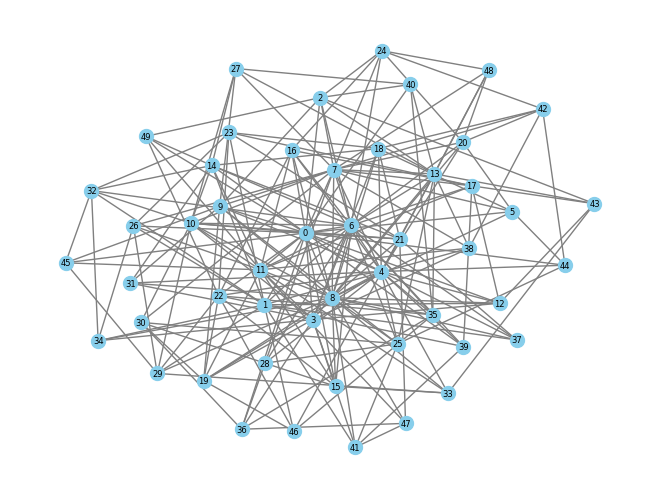

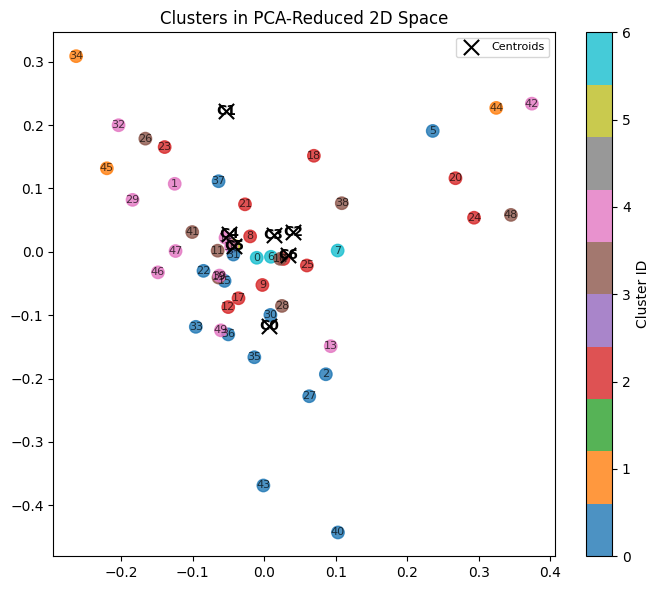

In [138]:
n=50
# graph = nx.random_regular_graph(n=n, d=3, seed=0)
graph = nx.barabasi_albert_graph(n=n, m=5, seed=0)
draw_graph_custom(graph, layout='kamada_kawai')
Y = graph_laplacian_embedding(graph, k=n-1, jump=2)
clusters, ordered_clusters, pca_coords = cluster_and_order_by_pca(list(range(n)), Y, num_clusters=7, method='kmeans', plot=True, pca_space=False)

In [182]:
graph.degree(0)

15

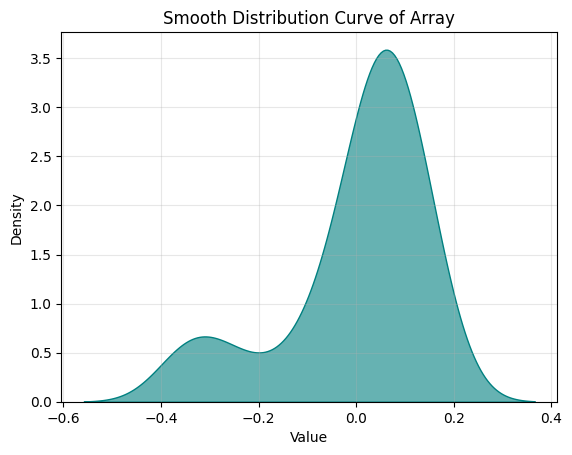

In [171]:
# graph = nx.barabasi_albert_graph(n=50, m=3, seed=2)
graph = nx.random_regular_graph(n=50, d=3, seed=0)
logical_embedding = graph_laplacian_embedding(graph, k=2, jump=1)
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

data = logical_embedding[:,0]

sns.kdeplot(data, fill=True, color='teal', alpha=0.6)
plt.xlabel("Value")
plt.ylabel("Density")
plt.title("Smooth Distribution Curve of Array")
plt.grid(alpha=0.3)
plt.show()


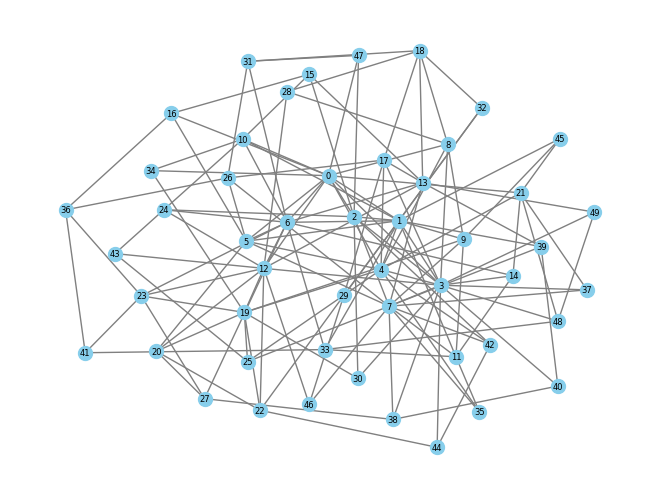

In [23]:
graph = barabasi_albert_graph(n=n, m=3, seed=1)
draw_graph_custom(graph)

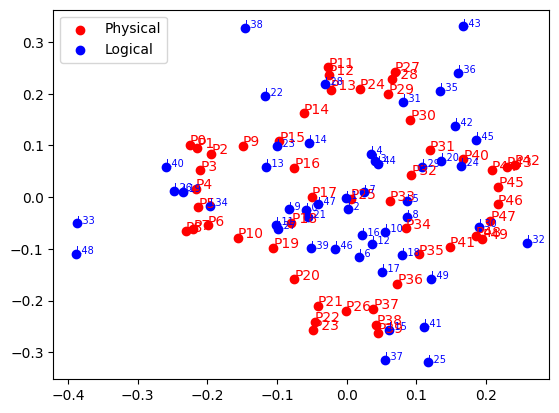

In [182]:
import matplotlib.pyplot as plt

n=50
# graph = nx.newman_watts_strogatz_graph(n=n, k=4, p=0.3, seed=0)
graph = barabasi_albert_graph(n=n, m=3, seed=0)
# graph = nx.random_regular_graph(n=n, d=3, seed=0)
logical_embedding = graph_laplacian_embedding(graph, k=2, normalized=False)
# logical_embedding = PCA(n_components=2).fit_transform(logical_embedding)
# logical_embedding = logical_embedding[:, 1:]

H = get_coupling_graph(FakeFez())
S = build_tree_cluster(H, source=H.number_of_nodes()//2, n=n)
physical_embedding = graph_laplacian_embedding(S, k=2)

# Physical embedding
plt.scatter(physical_embedding[:,0], physical_embedding[:,1], c='red', label='Physical')
for i, (x, y) in enumerate(physical_embedding):
    plt.text(x, y, f'P{i}', color='red')

# Logical embedding
plt.scatter(logical_embedding[:,0], logical_embedding[:,1], c='blue', label='Logical')
for i, (x, y) in enumerate(logical_embedding):
    plt.text(x, y, f'L{i}', color='blue', size=7)

plt.legend()
plt.show()

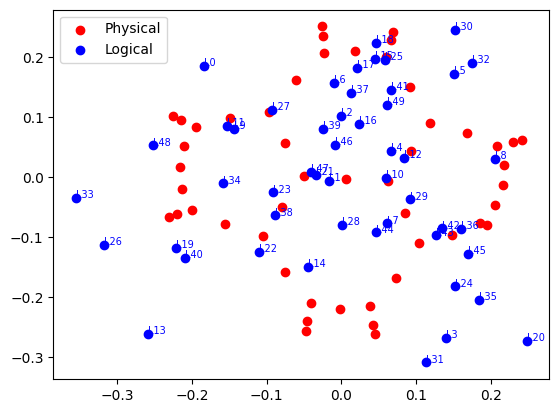

In [181]:
import matplotlib.pyplot as plt

n=50
# graph = nx.newman_watts_strogatz_graph(n=n, k=4, p=0.3, seed=0)
graph = barabasi_albert_graph(n=n, m=3, seed=0)
# graph = nx.random_regular_graph(n=n, d=3, seed=0)
logical_embedding = graph_laplacian_embedding(graph, k=2, normalized=True)
# logical_embedding = PCA(n_components=2).fit_transform(logical_embedding)
# logical_embedding = logical_embedding[:, 1:]

H = get_coupling_graph(FakeFez())
S = build_tree_cluster(H, source=H.number_of_nodes()//2, n=n)
physical_embedding = graph_laplacian_embedding(S, k=2)

# Physical embedding
plt.scatter(physical_embedding[:,0], physical_embedding[:,1], c='red', label='Physical')
# for i, (x, y) in enumerate(physical_embedding):
#     plt.text(x, y, f'P{i}', color='red')

# Logical embedding
plt.scatter(logical_embedding[:,0], logical_embedding[:,1], c='blue', label='Logical')
for i, (x, y) in enumerate(logical_embedding):
    plt.text(x, y, f'L{i}', color='blue', size=7)

plt.legend()
plt.show()

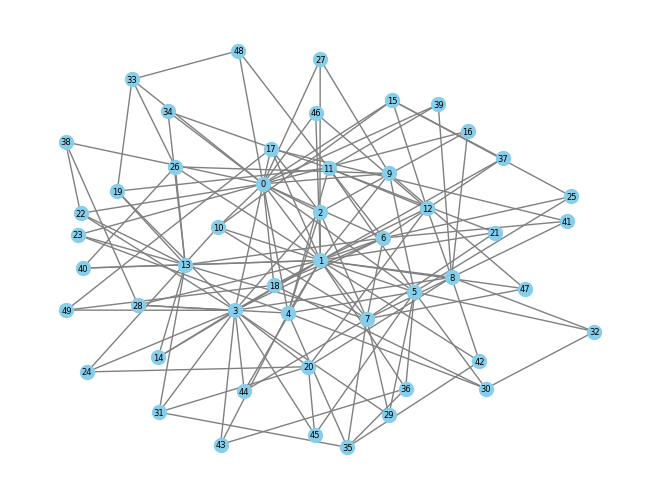

In [175]:
graph = barabasi_albert_graph(n=n, m=3, seed=0)
draw_graph_custom(graph)

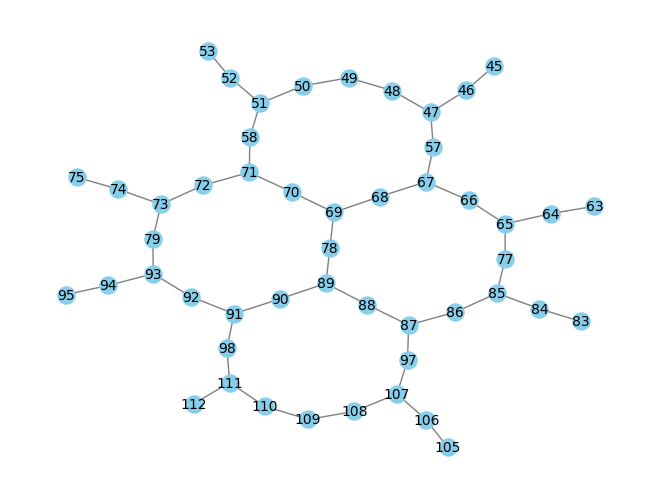

In [33]:
H = get_coupling_graph(FakeFez())
S = build_tree_cluster(H, source=H.number_of_nodes()//2, n=50)
# S = nx.random_regular_graph(n=50, d=3, seed=0)
draw_graph_custom(S, layout='kamada_kawai', font_size=10, node_size=150)

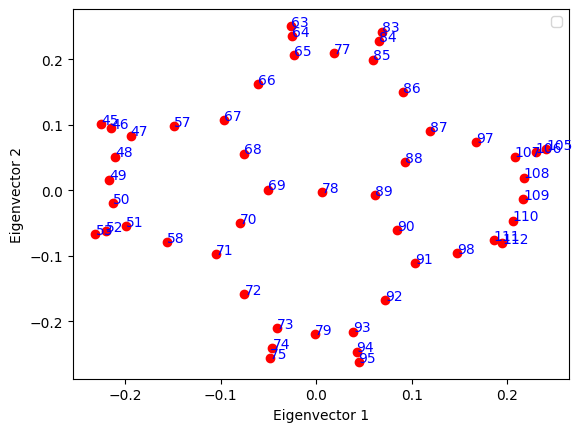

In [35]:
import matplotlib.pyplot as plt
# physical_embedding = graph_laplacian_embedding(S, k=2, normalized=True)
physical_embedding = graph_laplacian_embedding(S, k=2)

# Physical embedding
plt.scatter(physical_embedding[:,0], physical_embedding[:,1], c='red')
for i, (x, y) in enumerate(physical_embedding):
    plt.text(x, y, f'{sorted(S.nodes)[i]}', color='blue', size=10)

plt.xlabel("Eigenvector 1")
plt.ylabel("Eigenvector 2")
plt.legend()
plt.show()

In [12]:
backend.basis_gates

['cz', 'id', 'rz', 'sx', 'x']

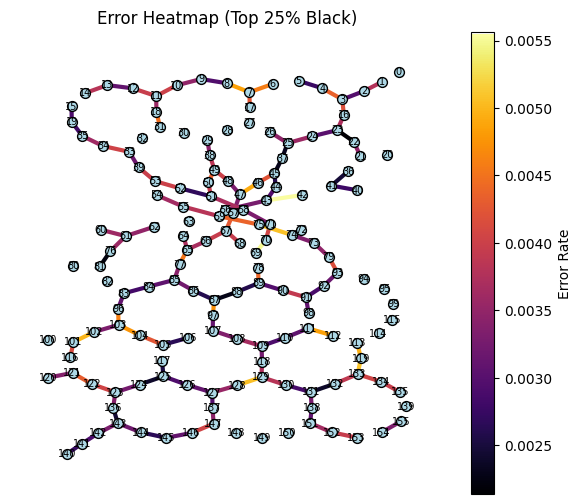

In [198]:
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np

def draw_hardware_gate_error_map(backend, cgate='cx', cap_percentile=95):
    """
    Draw hardware coupling graph colored by two-qubit gate error rates.
    Outliers above the given percentile are shown as black edges.

    Args:
        backend: Qiskit backend object (real or fake)
        cgate: 'cx', 'cz', etc.
        cap_percentile: percentile cutoff for color scaling (default: 95)
    """
    props = backend.properties()
    G = nx.Graph()

    # Extract two-qubit gate errors
    gate_errors = {}
    for gate in props.gates:
        if gate.gate == cgate:
            q1, q2 = gate.qubits
            err = next(param.value for param in gate.parameters if param.name == "gate_error")
            gate_errors[(q1, q2)] = err
            gate_errors[(q2, q1)] = err

    if not gate_errors:
        raise ValueError(f"No {cgate} gates found in backend properties.")
    
    G = get_coupling_graph(backend)

    errors = np.array(list(gate_errors.values()))
    cap_value = np.percentile(errors, cap_percentile)
    min_err = errors.min()

    # Create a truncated colormap: everything above cap_value -> black
    base_cmap = plt.cm.inferno
    colors = base_cmap(np.linspace(0, 1, 256))
    colors[-1] = [0, 0, 0, 0]  # set top color to black
    capped_cmap = mpl.colors.ListedColormap(colors)
    norm = mpl.colors.Normalize(vmin=min_err, vmax=cap_value)

    fig, ax = plt.subplots(figsize=(7, 6))
    pos = nx.kamada_kawai_layout(G)

    # Draw nodes
    nx.draw_networkx_nodes(G, pos, node_color='lightblue', node_size=50, edgecolors='black', ax=ax)

    # Draw edges — clamp values above cap_value
    edges = list(G.edges())
    edge_weights = [min(gate_errors[(u, v)], cap_value) for u, v in edges]
    nx.draw_networkx_edges(
        G, pos, edgelist=edges, edge_color=edge_weights, edge_cmap=capped_cmap,
        edge_vmin=min_err, edge_vmax=cap_value, width=3, ax=ax
    )

    nx.draw_networkx_labels(G, pos, font_size=7, font_color='black', ax=ax)

    sm = plt.cm.ScalarMappable(cmap=capped_cmap, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax)
    cbar.set_label(f"Error Rate", fontsize=10)

    ax.set_title(f"Error Heatmap (Top {100-cap_percentile}% Black)")
    ax.axis("off")
    plt.show()

draw_hardware_gate_error_map(FakeFez(), cgate='cz', cap_percentile=75)

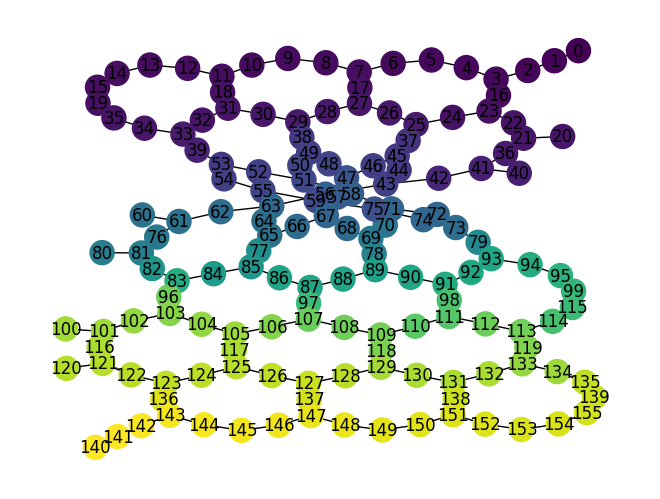

In [183]:
graph = get_coupling_graph(FakeFez(), weighted=True)
# draw_graph_custom(graph)
gradient_graph(graph)
# graph.edges(data=True)

In [186]:
graph.edges(data=True)

EdgeDataView([(72, 73, {'weight': np.float64(0.24879672729600955)}), (72, 71, {'weight': np.float64(0.9653194705141497)}), (73, 74, {'weight': np.float64(0.9970187546084998)}), (73, 79, {'weight': np.float64(0.24881144602293137)}), (7, 17, {'weight': np.float64(0.9948138721207375)}), (7, 6, {'weight': np.float64(0.9945625041107379)}), (7, 8, {'weight': np.float64(0.9954391078581604)}), (17, 27, {'weight': np.float64(0.9944636899277195)}), (67, 68, {'weight': np.float64(0.9906560682074488)}), (67, 57, {'weight': np.float64(0.9916700782352023)}), (67, 66, {'weight': np.float64(0.9906487474787415)}), (68, 69, {'weight': np.float64(0.24787906787603464)}), (44, 45, {'weight': np.float64(0.995933010786709)}), (44, 43, {'weight': np.float64(0.24766266990810404)}), (45, 46, {'weight': np.float64(0.9936531381437904)}), (45, 37, {'weight': np.float64(0.9966932734238791)}), (8, 9, {'weight': np.float64(0.9972396847812771)}), (9, 10, {'weight': np.float64(0.9968077835950808)}), (40, 41, {'weight':

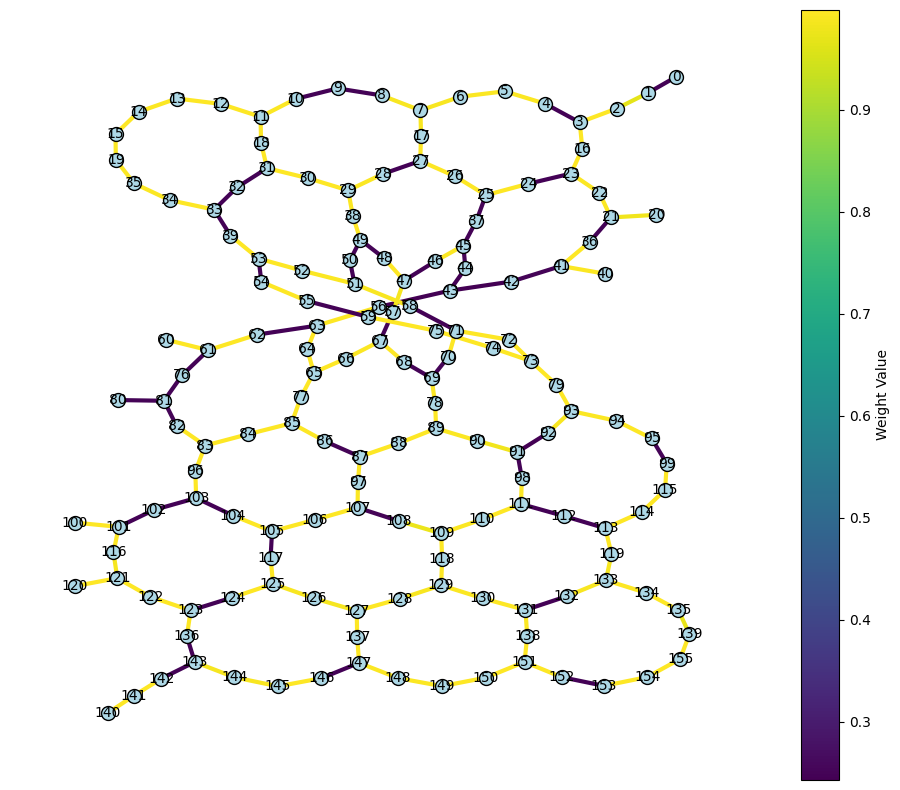

In [201]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np

def draw_weighted_graph(G, weight='weight', cmap='viridis', title=None, layout='kamada_kawai'):
    """
    Draws a weighted NetworkX graph with edge weights visualized as colors.
    Includes a colorbar that represents the edge weights.
    """
    # Extract weights
    edges = G.edges(data=True)
    weights = np.array([d.get(weight, 1.0) for _, _, d in edges])

    G = get_coupling_graph(backend)
    # Choose layout
    if layout == 'spring':
        pos = nx.spring_layout(G, seed=42)
    elif layout == 'kamada_kawai':
        pos = nx.kamada_kawai_layout(G)
    elif layout == 'circular':
        pos = nx.circular_layout(G)
    elif layout == 'shell':
        pos = nx.shell_layout(G)
    else:
        raise ValueError(f"Unsupported layout: {layout}")


    # Normalize weights for colormap
    norm = plt.Normalize(vmin=min(weights), vmax=max(weights))
    cmap_obj = plt.cm.get_cmap(cmap)

    # Create figure and axes
    fig, ax = plt.subplots(figsize=(12, 10))

    # Draw nodes and labels
    nx.draw_networkx_nodes(G, pos, node_color='lightblue', edgecolors='black', node_size=100, ax=ax)
    nx.draw_networkx_labels(G, pos, font_size=10, font_color='black', ax=ax)

    # Draw weighted edges
    nx.draw_networkx_edges(
        G, pos, edgelist=G.edges(),
        edge_color=weights, edge_cmap=cmap_obj,
        edge_vmin=min(weights), edge_vmax=max(weights),
        width=3, ax=ax
    )

    # Create ScalarMappable and add colorbar to the same figure
    sm = plt.cm.ScalarMappable(cmap=cmap_obj, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax)
    cbar.set_label(f"{weight.capitalize()} Value", fontsize=10)

    # Title and final adjustments
    if title:
        ax.set_title(title, fontsize=12)
    ax.axis('off')

    plt.show()


draw_weighted_graph(graph)

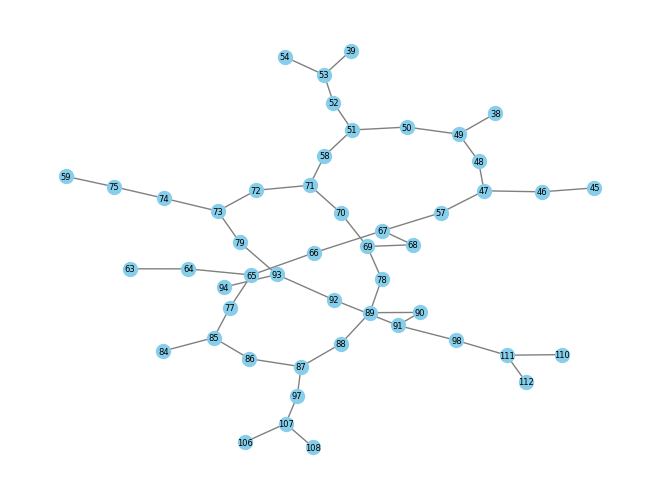

In [202]:
import networkx as nx
from collections import deque
import numpy as np

def bfs_weighted_subgraph_adaptive(G, source, n, weight='weight', threshold=0.5, relax_factor=0.5, min_threshold=0.0):
    """
    Extract a subgraph of exactly n nodes using BFS that adaptively relaxes the threshold
    when no new nodes can be added.

    Args:
        G (nx.Graph): Weighted graph
        source: Start node
        n (int): Desired number of nodes
        weight (str): Edge weight key
        threshold (float): Initial weight threshold for BFS traversal
        relax_factor (float): Multiplier to relax threshold (e.g. 0.8 → lower by 20%)
        min_threshold (float): Minimum threshold to stop relaxing

    Returns:
        nx.Graph: Subgraph of exactly n nodes
    """
    if source not in G:
        raise ValueError(f"Source node {source} not in graph")

    visited = set([source])
    q = deque([source])
    sub_nodes = [source]
    current_threshold = threshold

    while len(sub_nodes) < n:
        progress = False
        temp_q = deque(q)

        while temp_q and len(sub_nodes) < n:
            u = temp_q.popleft()
            for v in G.neighbors(u):
                if v not in visited:
                    w = G[u][v].get(weight, 1.0)
                    if w >= current_threshold:
                        visited.add(v)
                        q.append(v)
                        sub_nodes.append(v)
                        progress = True
                        if len(sub_nodes) >= n:
                            break

        # If no new nodes were added, relax the threshold
        if not progress:
            current_threshold *= relax_factor
            if current_threshold < min_threshold:
                # As a last resort, include any remaining nodes
                remaining = [v for v in G.nodes if v not in visited]
                sub_nodes.extend(remaining[: n - len(sub_nodes)])
                break

    return G.subgraph(sub_nodes).copy()

sub = bfs_weighted_subgraph_adaptive(graph, source=backend.num_qubits//2, n=50, threshold=0.9)
draw_graph_custom(sub)

In [205]:
conf = backend.configuration()
props = backend.properties()
for q in range(conf.num_qubits):
    qb = props.qubits[q]
    readout_err = qb[2].value
    t1, t2 = qb[0].value, qb[1].value
    decoh = (1 / t1 + 1 / t2) if t1 > 0 and t2 > 0 else 0
    gate_errs = [
        param.value
        for g in props.gates
        if len(g.qubits) == 1 and g.qubits[0] == q
        for param in g.parameters
        if param.name == "gate_error"
    ]
    avg_gate_err = np.mean(gate_errs) if gate_errs else 0
    print(t1, t2, decoh, readout_err, avg_gate_err)

48.806207822303335 42.37959748613206 0.0440854568356652 0.011474609375 0.0006112551522913244
255.7051713972407 302.79087382213305 0.007213363360344251 0.01171875 0.00014264126600461717
274.39425564238564 99.98472093525108 0.013645919301352944 0.0048828125 0.00015807264744828955
219.7204520004499 215.54352906307065 0.009190671784747917 0.015869140625 0.00019134926050980844
190.89711152782226 161.93208551009627 0.011413852346358267 0.00146484375 0.0001698885564879224
190.00369756073826 208.67352912905028 0.010055230138389146 0.007568359375 0.00022263729133623604
213.89581492590796 129.32418957378178 0.012407678730950247 0.0068359375 0.00020194762474377682
139.66754039700157 48.09582866528409 0.027951683645160742 0.02099609375 0.00023922304182862853
74.72402904127765 43.304613694704244 0.03647480373350704 0.004150390625 0.00022041710385958417
247.0175051075749 53.876279500303006 0.022609340194299415 0.007080078125 0.00019018440716930953
168.71045440453517 117.64823869333209 0.014427229713

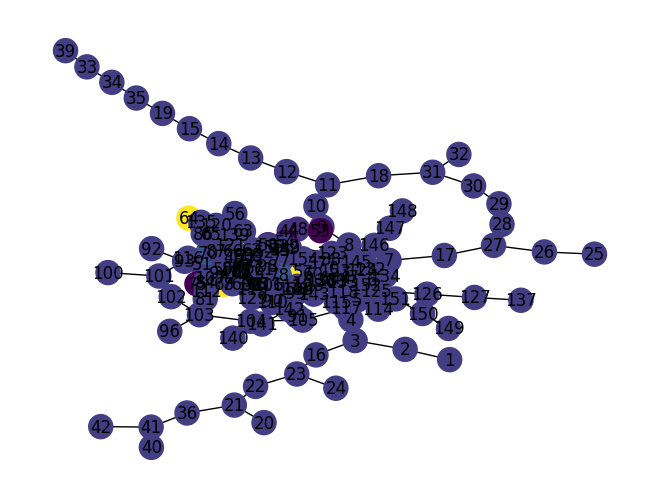

In [157]:
H = nx.Graph([
        (u, v, d) for u, v, d in graph.edges(data=True)
        if d["weight"] >= 0.9
    ])
H.add_nodes_from(graph.nodes(data=True))
gradient_graph(H)

In [ ]:
def find_low_noise_subgraph(G, reliability_threshold=0.9, target_size=16, visualize=True):
    """Finds a connected subgraph avoiding low-reliability edges."""
    # Filter out unreliable edges
    H = nx.Graph([
        (u, v, d) for u, v, d in G.edges(data=True)
        if d["reliability"] >= reliability_threshold
    ])
    H.add_nodes_from(G.nodes(data=True))  # retain node reliabilities

    # Get connected components sorted by size
    components = sorted(nx.connected_components(H), key=len, reverse=True)

    best_subgraph = None
    best_score = -np.inf

    for comp in components:
        if len(comp) < target_size:
            continue

        subG = H.subgraph(comp).copy()

        # Compute average reliability (node + edge)
        edge_rels = [d["reliability"] for _, _, d in subG.edges(data=True)]
        node_rels = [d["reliability"] for _, d in subG.nodes(data=True)]
        avg_reliability = (np.mean(edge_rels) + np.mean(node_rels)) / 2

        if avg_reliability > best_score:
            best_score = avg_reliability
            best_subgraph = subG

    if best_subgraph is None:
        print("⚠️ No subgraph of target size found above threshold. Try lowering threshold.")
        return None

    if visualize:
        pos = nx.kamada_kawai_layout(G)
        edge_colors = [
            "black" if (u, v) not in best_subgraph.edges() else "tab:blue"
            for u, v in G.edges()
        ]
        nx.draw(G, pos, node_color="lightgray", edge_color=edge_colors, alpha=0.5)
        nx.draw_networkx_nodes(best_subgraph, pos, node_color="tab:orange", node_size=200)
        nx.draw_networkx_labels(best_subgraph, pos, font_size=8, font_color="black")
        plt.title(f"Best Low-Noise Subgraph (avg reliability = {best_score:.3f})")
        plt.axis("off")
        plt.show()

    return best_subgraph

0.2784090909090909

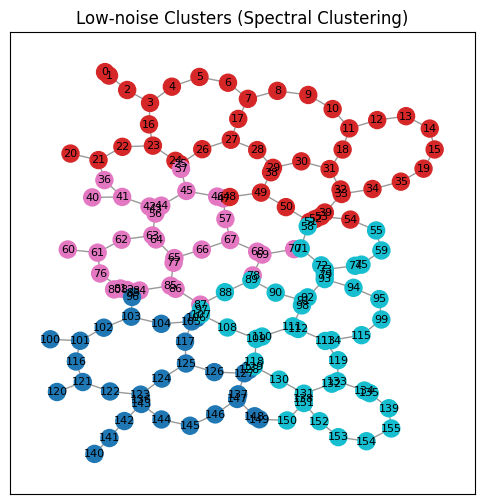

{0: [96, 100, 101, 102, 103, 104, 105, 106, 116, 117, 120, 121, 122, 123, 124, 125, 126, 127, 128, 136, 137, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149], 1: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 38, 39, 48, 49, 50, 51, 52, 53, 54], 2: [36, 37, 40, 41, 42, 43, 44, 45, 46, 47, 56, 57, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 76, 77, 78, 80, 81, 82, 83, 84, 85, 86, 87], 3: [55, 58, 59, 71, 72, 73, 74, 75, 79, 88, 89, 90, 91, 92, 93, 94, 95, 97, 98, 99, 107, 108, 109, 110, 111, 112, 113, 114, 115, 118, 119, 129, 130, 131, 132, 133, 134, 135, 138, 139, 150, 151, 152, 153, 154, 155]}


In [145]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import SpectralClustering

def cluster_low_noise_regions(G, num_clusters=4, plot=True):
    # Build adjacency matrix based on reliability (edge weights)
    A = nx.to_numpy_array(G, weight='weight')

    # Apply spectral clustering
    clustering = SpectralClustering(
        n_clusters=num_clusters,
        affinity='precomputed',
        assign_labels='kmeans',
        random_state=0
    )
    labels = clustering.fit_predict(A)

    clusters = {i: [] for i in range(num_clusters)}
    for node, label in zip(G.nodes(), labels):
        clusters[label].append(node)

    if plot:
        pos = nx.kamada_kawai_layout(G)
        plt.figure(figsize=(6, 6))
        nx.draw_networkx_nodes(G, pos, node_color=labels, cmap='tab10', node_size=150)
        nx.draw_networkx_edges(G, pos, alpha=0.4)
        nx.draw_networkx_labels(G, pos, font_size=8)
        plt.title("Low-noise Clusters (Spectral Clustering)")
        plt.show()

    return clusters

G = get_coupling_graph(backend, weighted=True)
clusters = cluster_low_noise_regions(G, num_clusters=4, plot=True)
print(clusters)


In [ ]:
import networkx as nx
import numpy as np

def get_noise_aware_subgraph(backend, k, alpha=0.7, beta_readout=0.5, beta_t12=0.2, beta_gate=0.3):
    """
    Extract a connected subgraph of `k` qubits from the hardware topology
    that balances connectivity and low noise.

    Parameters:
        backend: Qiskit backend (real or fake)
        k: number of qubits desired in subgraph
        alpha: weighting between edge (2Q) noise and node (1Q) noise
        beta_*: weights for readout, decoherence (T1/T2), and 1Q gate errors
    """
    props = backend.properties()
    conf = backend.configuration()
    coupling = conf.coupling_map

    G = nx.Graph()
    G.add_nodes_from(range(conf.num_qubits))

    # ---- Node (1Q) noise ----
    node_noise = {}
    for q in range(conf.num_qubits):
        qb = props.qubits[q]
        readout_err = qb[0].value
        t1, t2 = qb[1].value, qb[2].value
        decoh = (1 / t1 + 1 / t2) if t1 > 0 and t2 > 0 else 0
        gate_errs = [
            param.value
            for g in props.gates
            if len(g.qubits) == 1 and g.qubits[0] == q
            for param in g.parameters
            if param.name == "gate_error"
        ]
        avg_gate_err = np.mean(gate_errs) if gate_errs else 0
        node_noise[q] = (
            beta_readout * readout_err
            + beta_t12 * decoh
            + beta_gate * avg_gate_err
        )

    # ---- Edge (2Q) noise ----
    for g in props.gates:
        if len(g.qubits) == 2:
            q1, q2 = g.qubits
            err = next(param.value for param in g.parameters if param.name == "gate_error")
            node_term = (node_noise[q1] + node_noise[q2]) / 2
            combined_noise = alpha * err + (1 - alpha) * node_term
            reliability = 1 - combined_noise
            G.add_edge(q1, q2, weight=max(reliability, 0))

    # ---- Find subgraph of size k with high average reliability ----
    best_subgraph = None
    best_score = -1

    for node in G.nodes():
        sub = nx.ego_graph(G, node, radius=3)  # small local region
        if len(sub) < k:
            continue
        # Pick top-k most reliable nodes in this region
        weights = np.array([np.mean([d['weight'] for _,_,d in G.edges(n, data=True)]) for n in sub.nodes()])
        top_nodes = np.array(list(sub.nodes()))[np.argsort(weights)[-k:]]
        subG = G.subgraph(top_nodes)
        if nx.is_connected(subG):
            avg_reliability = np.mean([d['weight'] for _,_,d in subG.edges(data=True)])
            if avg_reliability > best_score:
                best_score = avg_reliability
                best_subgraph = subG

    return best_subgraph

# Example usage:
backend = FakeFez()
S = get_noise_aware_subgraph(backend, k=50)
gradient_graph(S)

AttributeError: 'NoneType' object has no attribute 'nodes'

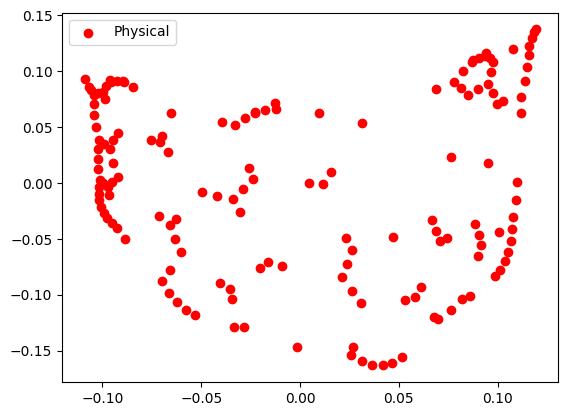

In [144]:
import matplotlib.pyplot as plt
physical_embedding = graph_laplacian_embedding(graph, k=2)

# Physical embedding
plt.scatter(physical_embedding[:,0], physical_embedding[:,1], c='red', label='Physical')

plt.legend()
plt.show()

In [209]:
props=backend.properties()
cgate='cz'
gate_errors = {}
for gate in props.gates:
    if gate.gate == cgate:
        q1, q2 = gate.qubits
        err = next(param.value for param in gate.parameters if param.name == "gate_error")
        gate_errors[(q1, q2)] = err
        gate_errors[(q2, q1)] = err
embedding = gate_errors.values()
min(embedding)

0.0021389143724314663

In [207]:
errors = np.array(list(gate_errors.values()))
np.percentile(errors, 99)

np.float64(1.0)

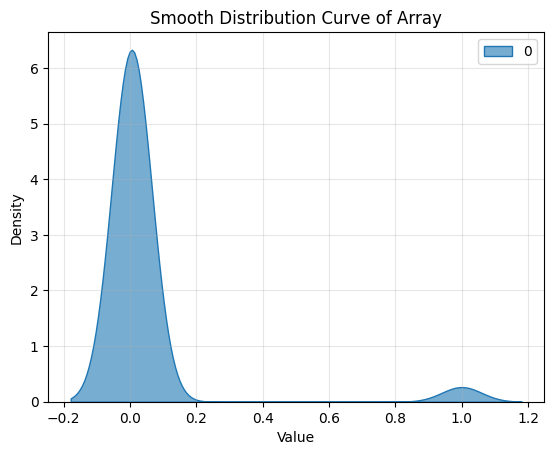

In [185]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

data = embedding

sns.kdeplot(data, fill=True, color='teal', alpha=0.6)
plt.xlabel("Value")
plt.ylabel("Density")
plt.title("Smooth Distribution Curve of Array")
plt.grid(alpha=0.3)
plt.show()


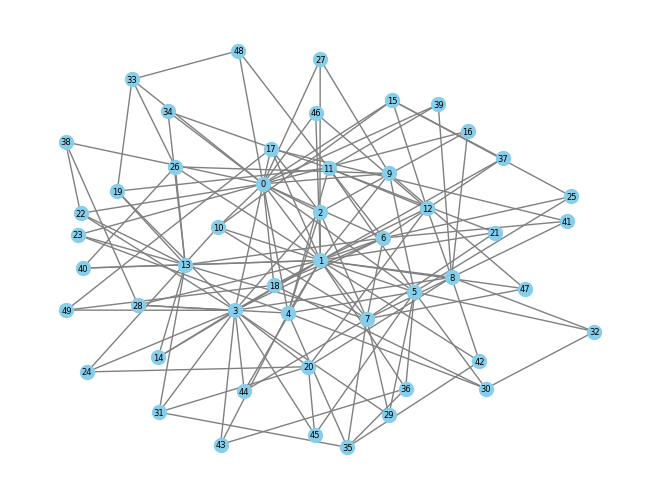

In [17]:
graph = barabasi_albert_graph(n=50, m=3, seed=0)
draw_graph_custom(graph)

In [13]:
graph = get_coupling_graph(backend)
graph.degree

DegreeView({0: 1, 1: 2, 2: 2, 3: 3, 4: 2, 16: 2, 5: 2, 6: 2, 7: 3, 8: 2, 17: 2, 9: 2, 10: 2, 11: 3, 12: 2, 18: 2, 13: 2, 14: 2, 15: 2, 19: 2, 23: 3, 27: 3, 31: 3, 35: 2, 20: 1, 21: 3, 22: 2, 36: 2, 24: 2, 25: 3, 26: 2, 37: 2, 28: 2, 29: 3, 30: 2, 38: 2, 32: 2, 33: 3, 34: 2, 39: 2, 41: 3, 45: 3, 49: 3, 53: 3, 40: 1, 42: 2, 43: 3, 44: 2, 56: 2, 46: 2, 47: 3, 48: 2, 57: 2, 50: 2, 51: 3, 52: 2, 58: 2, 54: 2, 55: 2, 59: 2, 63: 3, 67: 3, 71: 3, 75: 2, 60: 1, 61: 3, 62: 2, 76: 2, 64: 2, 65: 3, 66: 2, 77: 2, 68: 2, 69: 3, 70: 2, 78: 2, 72: 2, 73: 3, 74: 2, 79: 2, 81: 3, 85: 3, 89: 3, 93: 3, 80: 1, 82: 2, 83: 3, 84: 2, 96: 2, 86: 2, 87: 3, 88: 2, 97: 2, 90: 2, 91: 3, 92: 2, 98: 2, 94: 2, 95: 2, 99: 2, 103: 3, 107: 3, 111: 3, 115: 2, 100: 1, 101: 3, 102: 2, 116: 2, 104: 2, 105: 3, 106: 2, 117: 2, 108: 2, 109: 3, 110: 2, 118: 2, 112: 2, 113: 3, 114: 2, 119: 2, 121: 3, 125: 3, 129: 3, 133: 3, 120: 1, 122: 2, 123: 3, 124: 2, 136: 2, 126: 2, 127: 3, 128: 2, 137: 2, 130: 2, 131: 3, 132: 2, 138: 2, 13

In [38]:
n=50
# graph = nx.barabasi_albert_graph(n=n, m=3, seed=0)
graph = nx.random_regular_graph(n=n, d=3, seed=0)
logical_embedding = graph_laplacian_embedding(graph, k=2)
# pca_embedding = PCA(n_components=2).fit_transform(logical_embedding)

H = get_coupling_graph(FakeFez())
S = build_tree_cluster(H, source=H.number_of_nodes()//2, n=n)
physical_embedding = graph_laplacian_embedding(S, k=2)

mapping = optimal_qubit_assignment(logical_embedding, physical_embedding, nodes=sorted(S.nodes()))
mapping

{0: 65,
 1: 77,
 2: 105,
 3: 85,
 4: 79,
 5: 111,
 6: 72,
 7: 46,
 8: 58,
 9: 110,
 10: 51,
 11: 75,
 12: 90,
 13: 112,
 14: 98,
 15: 73,
 16: 53,
 17: 88,
 18: 67,
 19: 86,
 20: 95,
 21: 94,
 22: 57,
 23: 83,
 24: 78,
 25: 107,
 26: 69,
 27: 64,
 28: 89,
 29: 106,
 30: 87,
 31: 71,
 32: 109,
 33: 49,
 34: 68,
 35: 66,
 36: 70,
 37: 91,
 38: 108,
 39: 63,
 40: 84,
 41: 50,
 42: 74,
 43: 48,
 44: 97,
 45: 92,
 46: 47,
 47: 52,
 48: 45,
 49: 93}

Fiedler Mapped

In [48]:
import matplotlib.pyplot as plt

nodes_reg = list(range(6, 101, 2))
params_reg = list(range(3,6,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_reg={}
for param in params_reg:
    swaps_reg[param] = return_ops(backend, graph_type='reg', param=param, tree_type='dfs',
                         average_over=100, node_list=nodes_reg, tech='1D',
                         topology='tree_dfs', op_name='swap', use_custom=True, opt_level=3, stop_after_routing=True, reps=1)

Iterating for number of nodes:   0%|          | 0/48 [00:00<?, ?it/s]

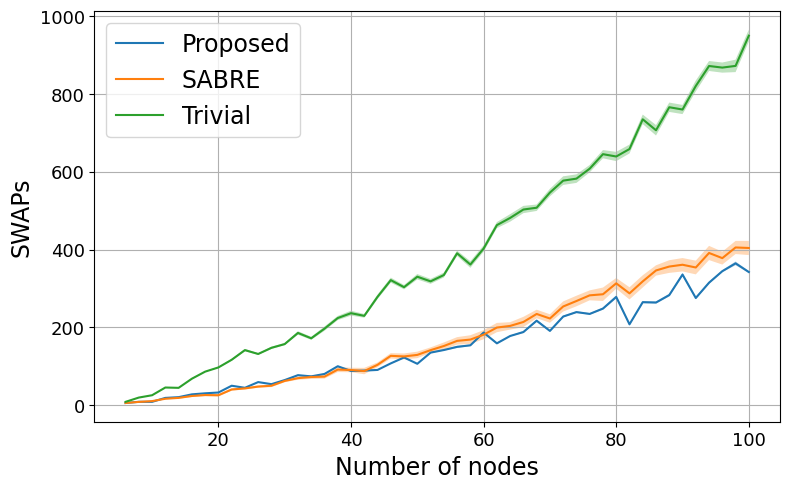

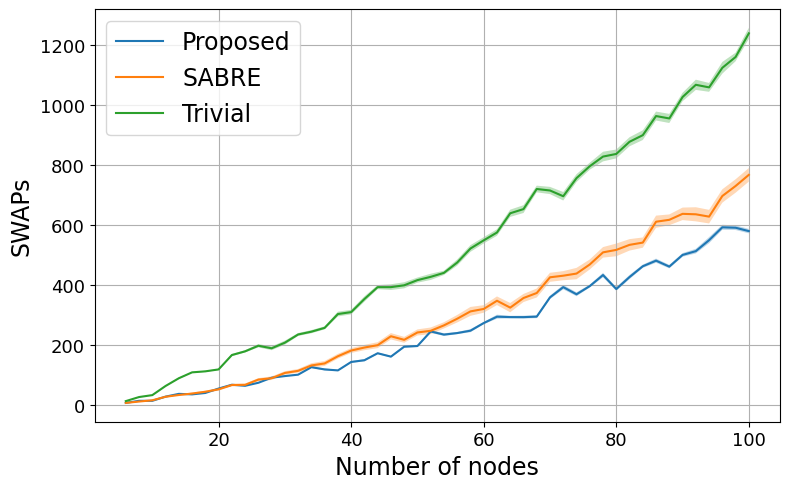

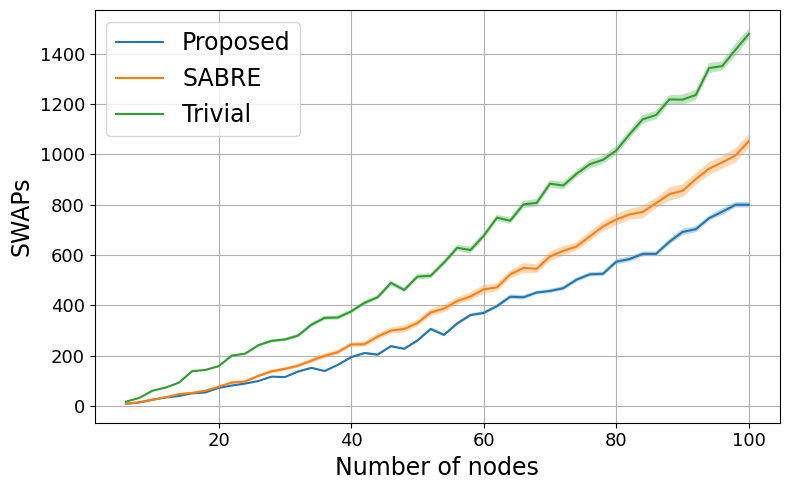

In [49]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_reg:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_reg[param]['means'][method])
        std = np.array(swaps_reg[param]['stddevs'][method])
        plt.plot(nodes_reg, mean, label=method)  # line for mean
        plt.fill_between(nodes_reg, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.legend(fontsize=17)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


2D Mapped

In [ ]:
import matplotlib.pyplot as plt

nodes_reg = list(range(6, 101, 2))
params_reg = list(range(3,6,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_reg={}
for param in params_reg:
    swaps_reg[param] = return_ops(backend, graph_type='reg', param=param, tree_type='dfs',
                         average_over=100, node_list=nodes_reg, tech='2D',
                         topology='tree_dfs', op_name='swap', use_custom=True, opt_level=3, stop_after_routing=True, reps=1)

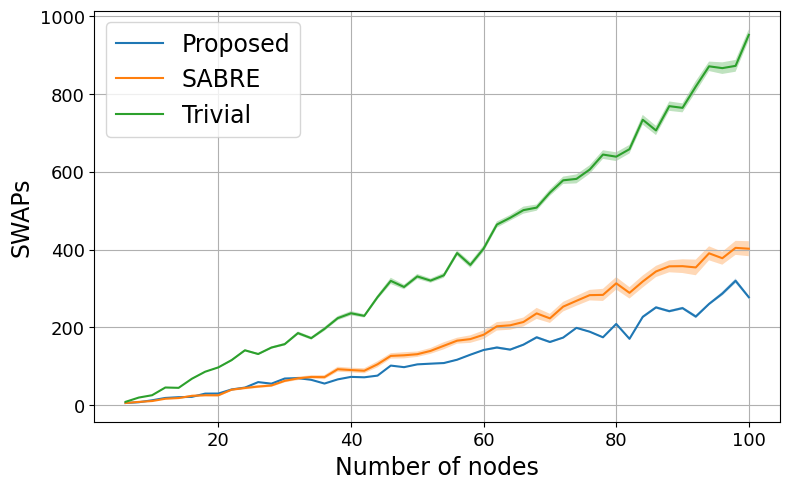

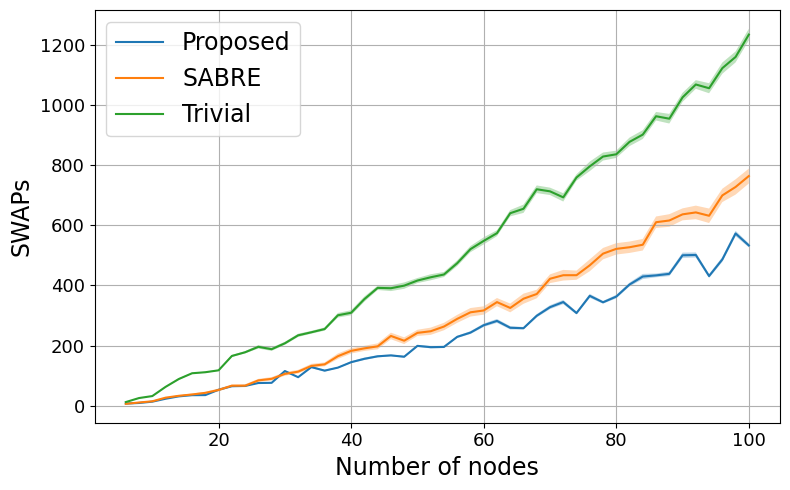

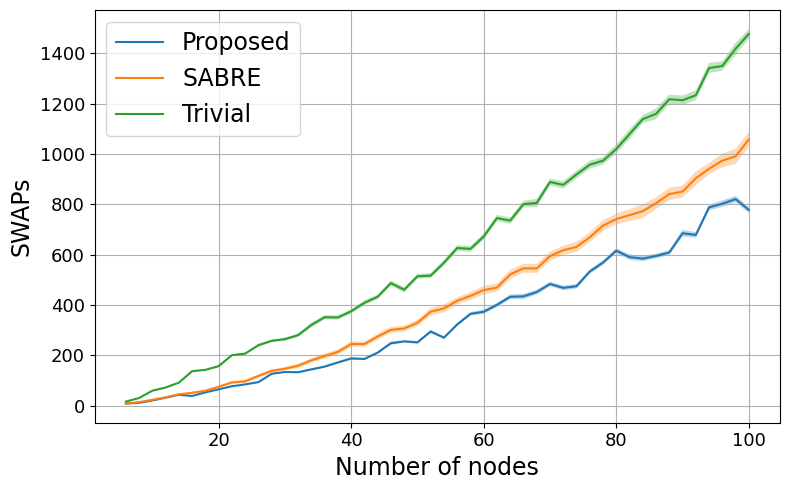

In [55]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_reg:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_reg[param]['means'][method])
        std = np.array(swaps_reg[param]['stddevs'][method])
        plt.plot(nodes_reg, mean, label=method)  # line for mean
        plt.fill_between(nodes_reg, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.legend(fontsize=17)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


2D Mapped with normalized edges

In [77]:
import matplotlib.pyplot as plt

nodes_reg = list(range(6, 101, 2))
params_reg = list(range(3,6,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_reg={}
for param in params_reg:
    swaps_reg[param] = return_ops(backend, graph_type='reg', param=param, normalize_graph=True,
                         average_over=100, node_list=nodes_reg, tech='2D',
                         topology='tree_dfs', op_name='swap', use_custom=True, opt_level=3, stop_after_routing=True, reps=1)

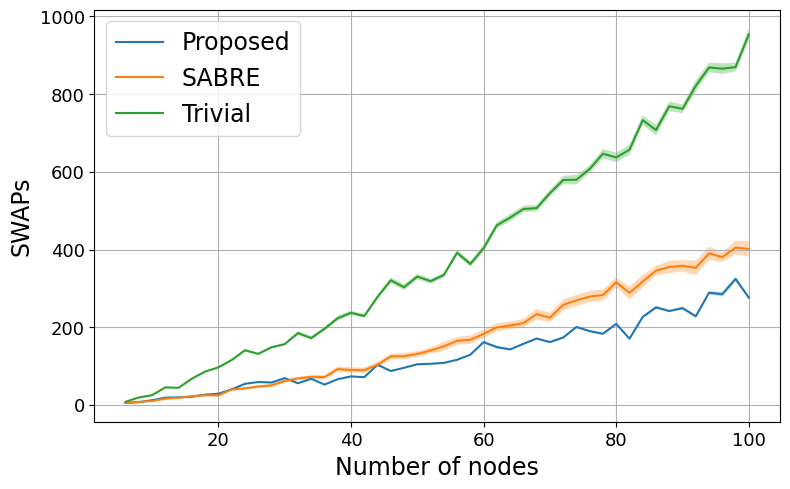

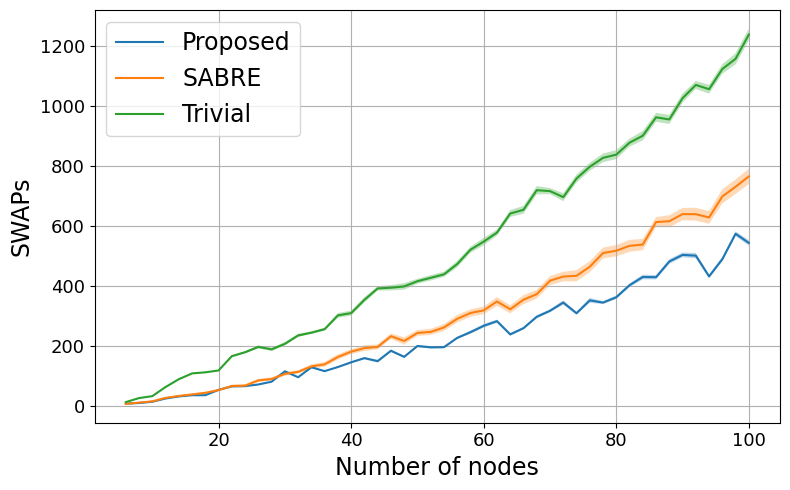

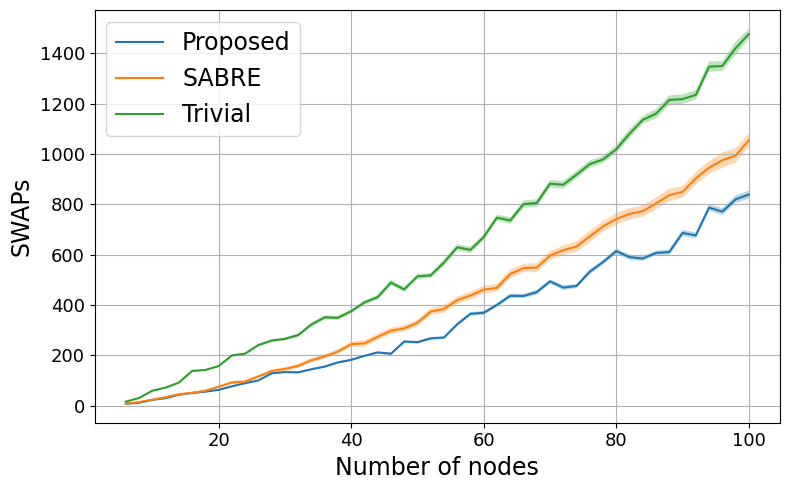

In [78]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_reg:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_reg[param]['means'][method])
        std = np.array(swaps_reg[param]['stddevs'][method])
        plt.plot(nodes_reg, mean, label=method)  # line for mean
        plt.fill_between(nodes_reg, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.legend(fontsize=17)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


2D Mapped with normalized laplacian

In [79]:
import matplotlib.pyplot as plt

nodes_reg = list(range(6, 101, 2))
params_reg = list(range(3,6,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_reg={}
for param in params_reg:
    swaps_reg[param] = return_ops(backend, graph_type='reg', param=param, normalize_laplacian=True,
                         average_over=100, node_list=nodes_reg, tech='2D',
                         topology='tree_dfs', op_name='swap', use_custom=True, opt_level=3, stop_after_routing=True, reps=1)

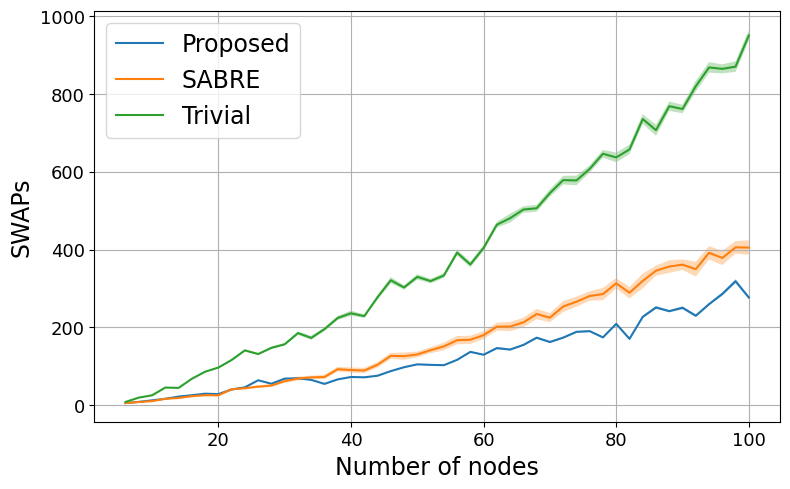

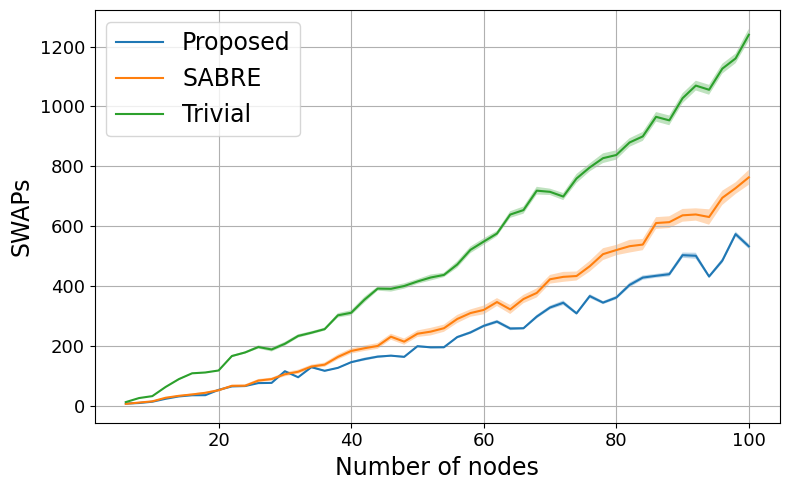

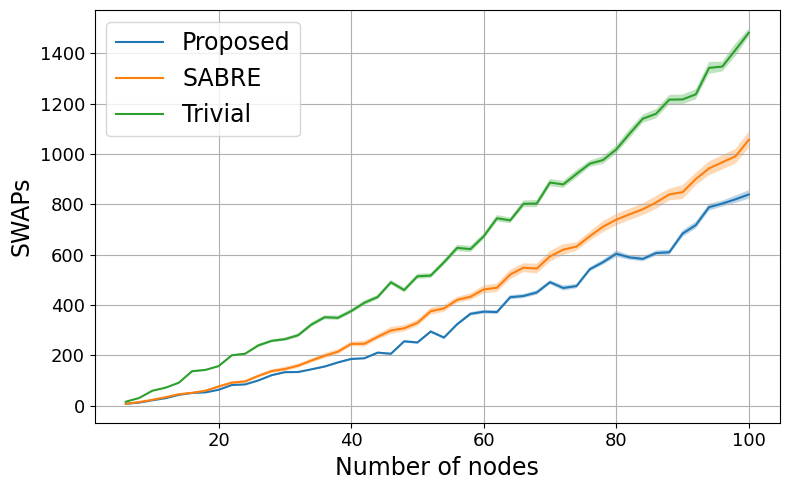

In [80]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_reg:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_reg[param]['means'][method])
        std = np.array(swaps_reg[param]['stddevs'][method])
        plt.plot(nodes_reg, mean, label=method)  # line for mean
        plt.fill_between(nodes_reg, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.legend(fontsize=17)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


3D Mapped

In [101]:
import matplotlib.pyplot as plt

nodes_reg = list(range(6, 101, 2))
params_reg = list(range(3,6,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_reg={}
for param in params_reg:
    swaps_reg[param] = return_ops(backend, graph_type='reg', param=param,
                         average_over=100, node_list=nodes_reg, tech='2D', k=3,
                         topology='tree_dfs', op_name='swap', use_custom=True, opt_level=3, stop_after_routing=True, reps=1)

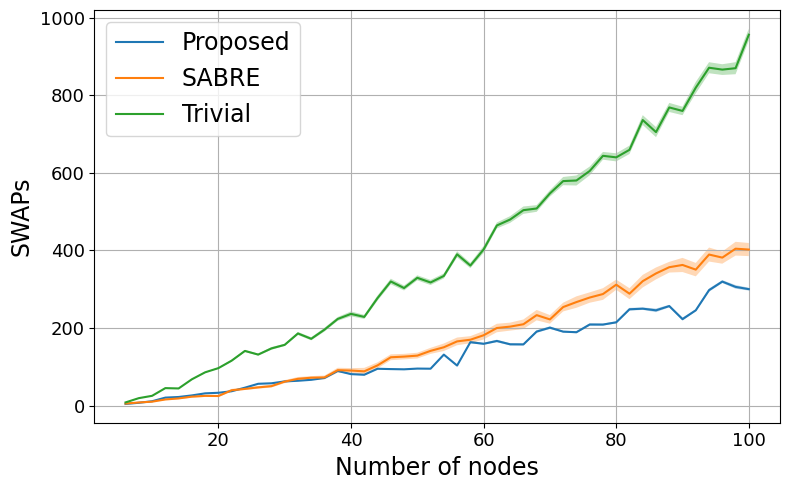

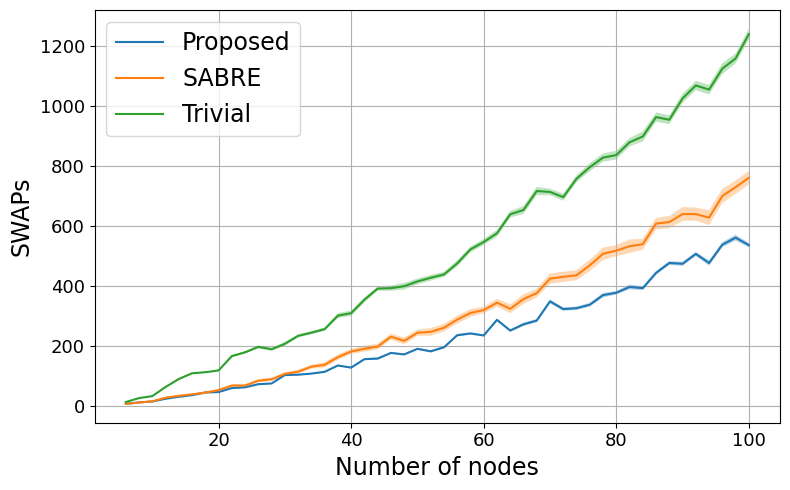

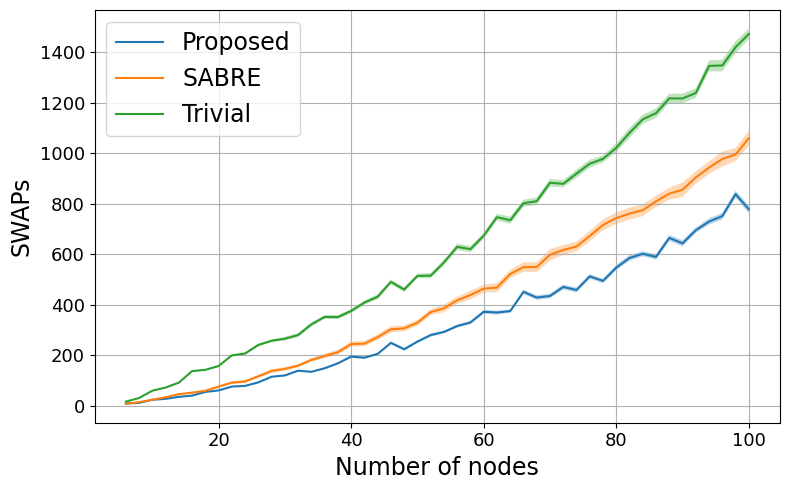

In [102]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_reg:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_reg[param]['means'][method])
        std = np.array(swaps_reg[param]['stddevs'][method])
        plt.plot(nodes_reg, mean, label=method)  # line for mean
        plt.fill_between(nodes_reg, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.legend(fontsize=17)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


3D Mapped with normalized edges

In [103]:
import matplotlib.pyplot as plt

nodes_reg = list(range(6, 101, 2))
params_reg = list(range(3,6,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_reg={}
for param in params_reg:
    swaps_reg[param] = return_ops(backend, graph_type='reg', param=param, normalize_graph=True,
                         average_over=100, node_list=nodes_reg, tech='2D', k=3,
                         topology='tree_dfs', op_name='swap', use_custom=True, opt_level=3, stop_after_routing=True, reps=1)

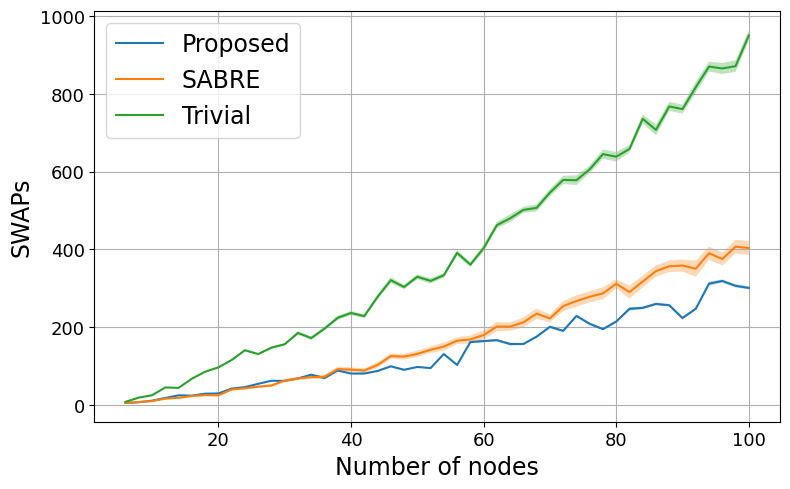

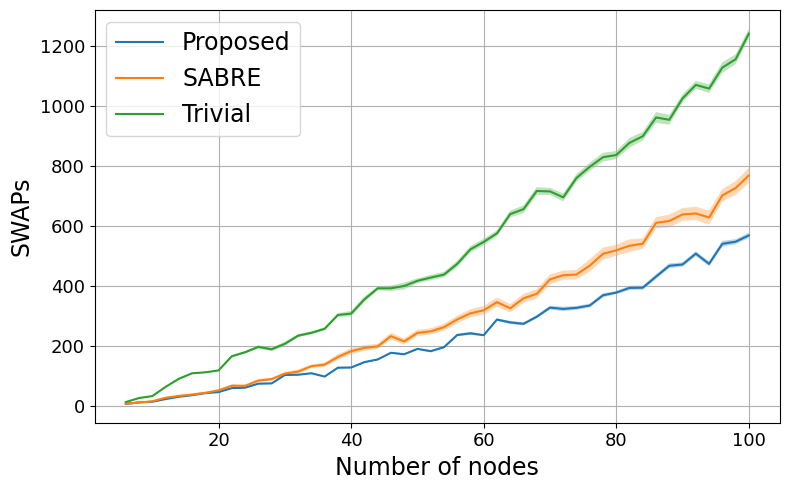

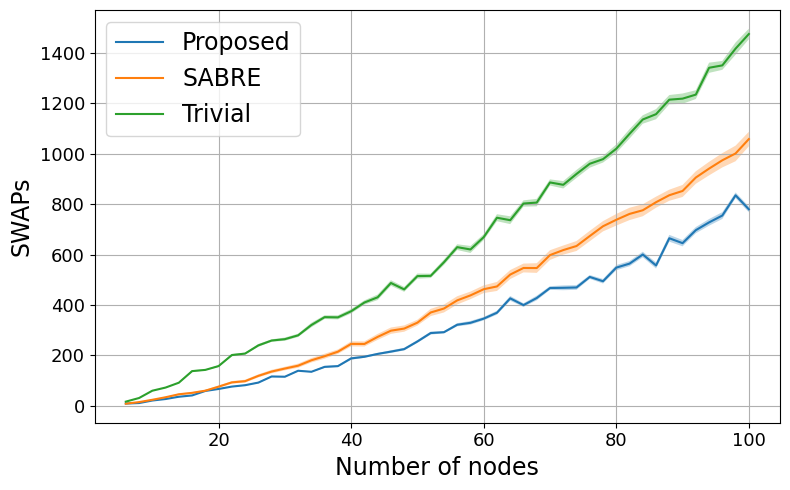

In [104]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_reg:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_reg[param]['means'][method])
        std = np.array(swaps_reg[param]['stddevs'][method])
        plt.plot(nodes_reg, mean, label=method)  # line for mean
        plt.fill_between(nodes_reg, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.legend(fontsize=17)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


3D Mapped with normalized laplacian

In [105]:
import matplotlib.pyplot as plt

nodes_reg = list(range(6, 101, 2))
params_reg = list(range(3,6,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_reg={}
for param in params_reg:
    swaps_reg[param] = return_ops(backend, graph_type='reg', param=param, normalize_laplacian=True,
                         average_over=100, node_list=nodes_reg, tech='2D', k=3,
                         topology='tree_dfs', op_name='swap', use_custom=True, opt_level=3, stop_after_routing=True, reps=1)

Iterating for number of nodes:   0%|          | 0/48 [00:00<?, ?it/s]

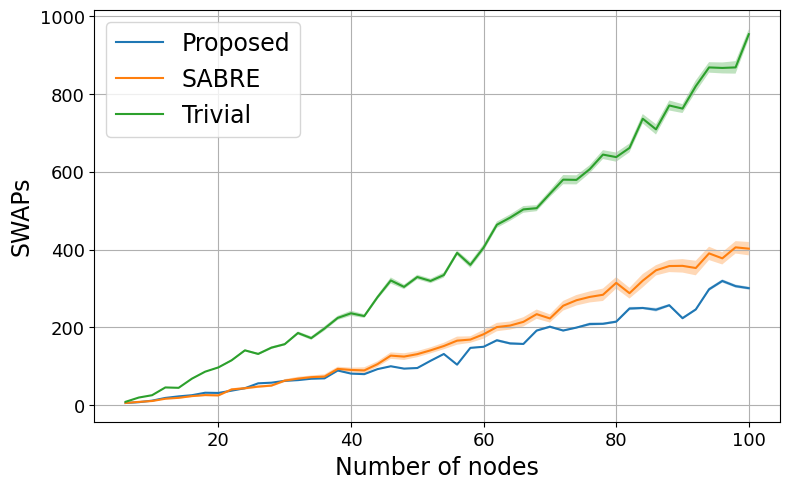

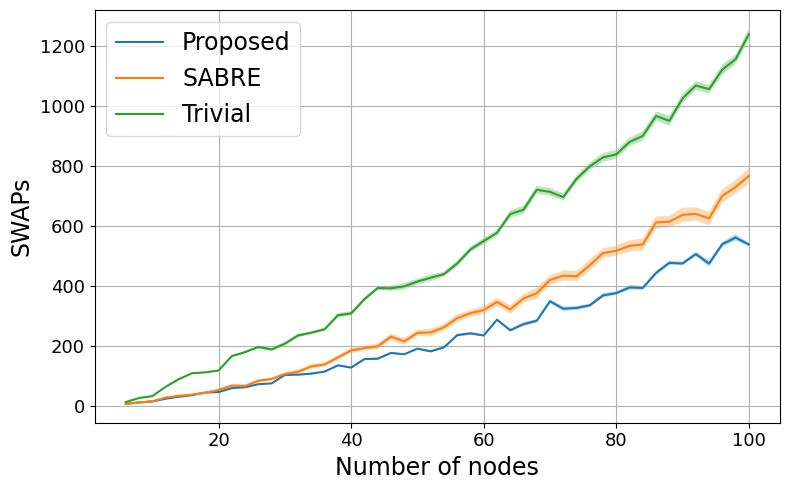

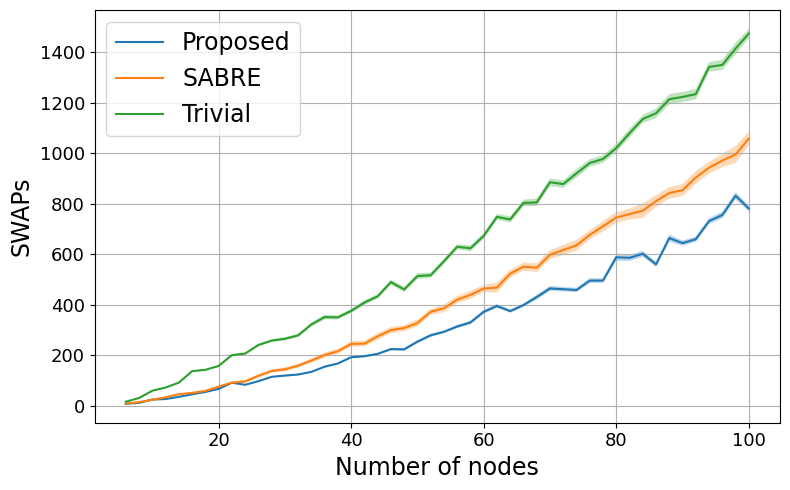

In [106]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_reg:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_reg[param]['means'][method])
        std = np.array(swaps_reg[param]['stddevs'][method])
        plt.plot(nodes_reg, mean, label=method)  # line for mean
        plt.fill_between(nodes_reg, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.legend(fontsize=17)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


5D Mapped

In [81]:
import matplotlib.pyplot as plt

nodes_reg = list(range(6, 101, 2))
params_reg = list(range(3,6,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_reg={}
for param in params_reg:
    swaps_reg[param] = return_ops(backend, graph_type='reg', param=param,
                         average_over=100, node_list=nodes_reg, tech='2D', k=5,
                         topology='tree_dfs', op_name='swap', use_custom=True, opt_level=3, stop_after_routing=True, reps=1)

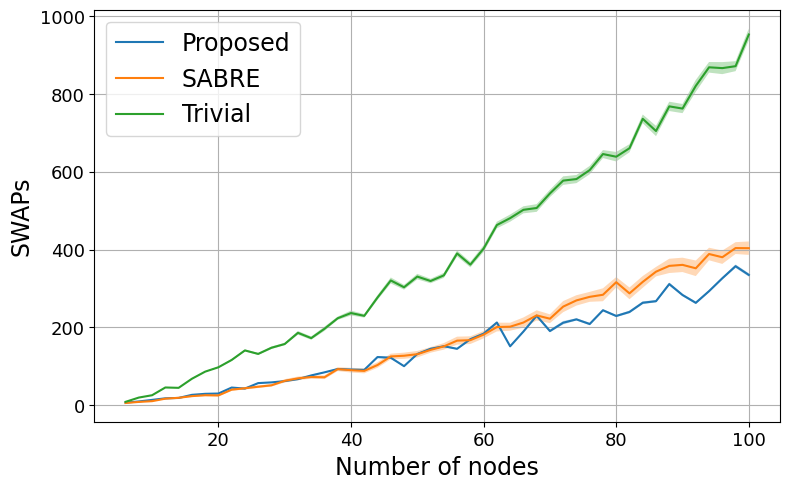

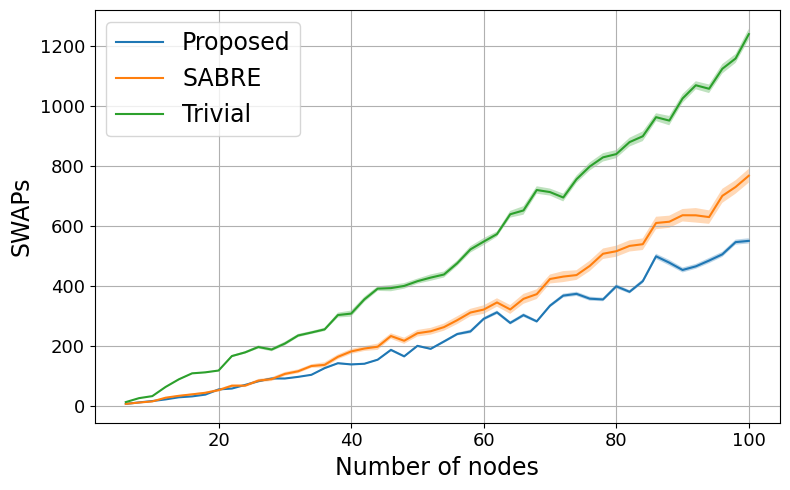

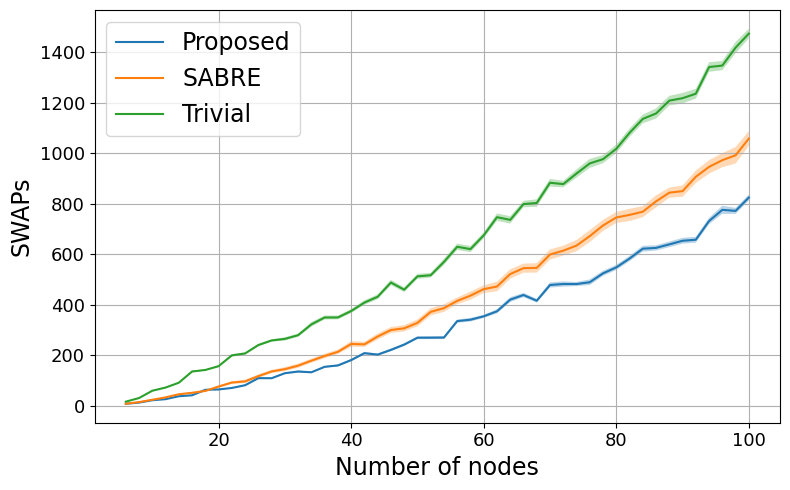

In [82]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_reg:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_reg[param]['means'][method])
        std = np.array(swaps_reg[param]['stddevs'][method])
        plt.plot(nodes_reg, mean, label=method)  # line for mean
        plt.fill_between(nodes_reg, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.legend(fontsize=17)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


5D Mapped with normalized edges

In [83]:
import matplotlib.pyplot as plt

nodes_reg = list(range(6, 101, 2))
params_reg = list(range(3,6,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_reg={}
for param in params_reg:
    swaps_reg[param] = return_ops(backend, graph_type='reg', param=param, normalize_graph=True,
                         average_over=100, node_list=nodes_reg, tech='2D', k=5,
                         topology='tree_dfs', op_name='swap', use_custom=True, opt_level=3, stop_after_routing=True, reps=1)

Iterating for number of nodes:   0%|          | 0/48 [00:00<?, ?it/s]

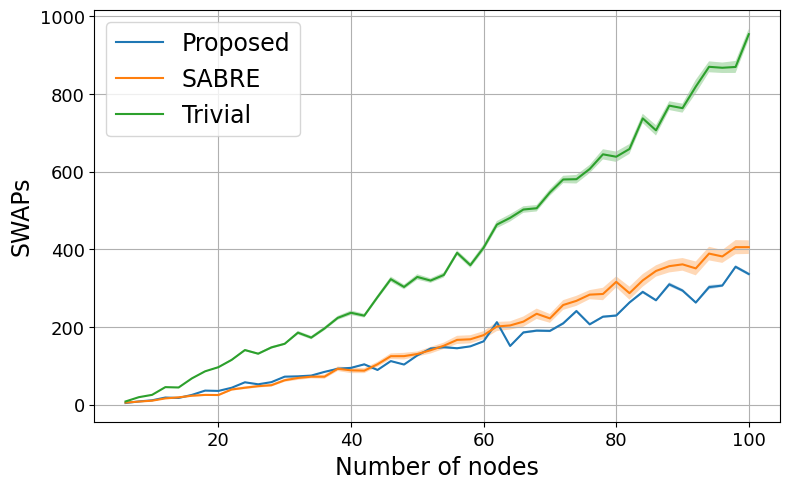

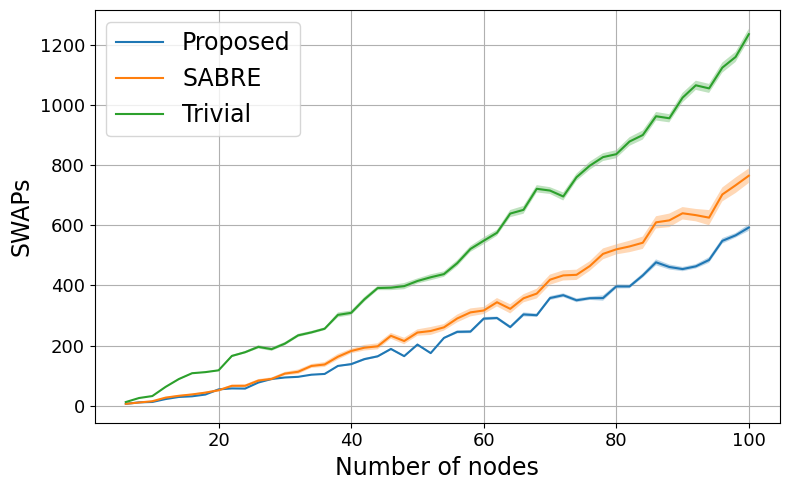

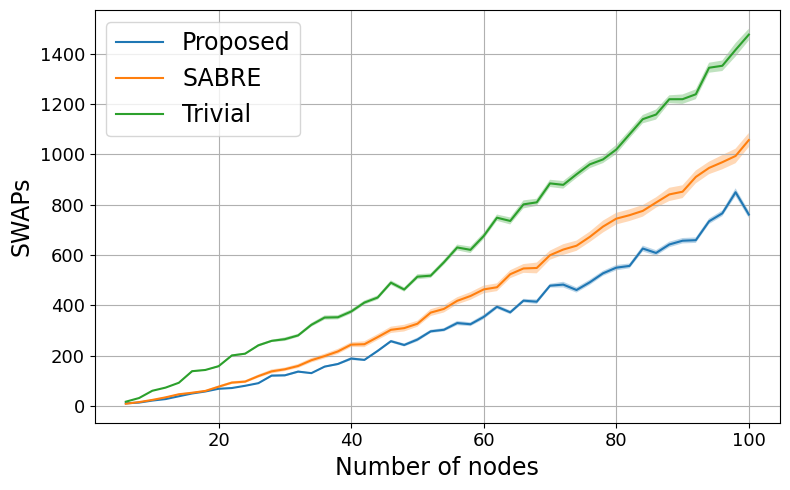

In [84]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_reg:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_reg[param]['means'][method])
        std = np.array(swaps_reg[param]['stddevs'][method])
        plt.plot(nodes_reg, mean, label=method)  # line for mean
        plt.fill_between(nodes_reg, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.legend(fontsize=17)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


5D Mapped with normalized laplacian

In [85]:
import matplotlib.pyplot as plt

nodes_reg = list(range(6, 101, 2))
params_reg = list(range(3,6,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_reg={}
for param in params_reg:
    swaps_reg[param] = return_ops(backend, graph_type='reg', param=param, normalize_laplacian=True,
                         average_over=100, node_list=nodes_reg, tech='2D', k=5,
                         topology='tree_dfs', op_name='swap', use_custom=True, opt_level=3, stop_after_routing=True, reps=1)

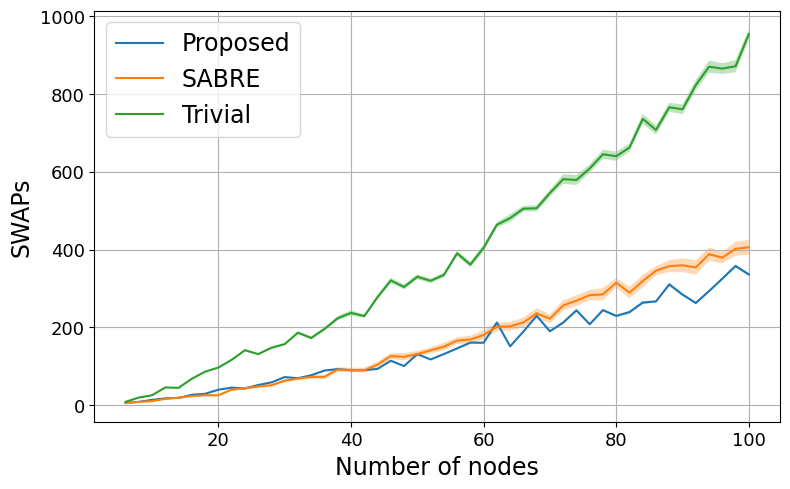

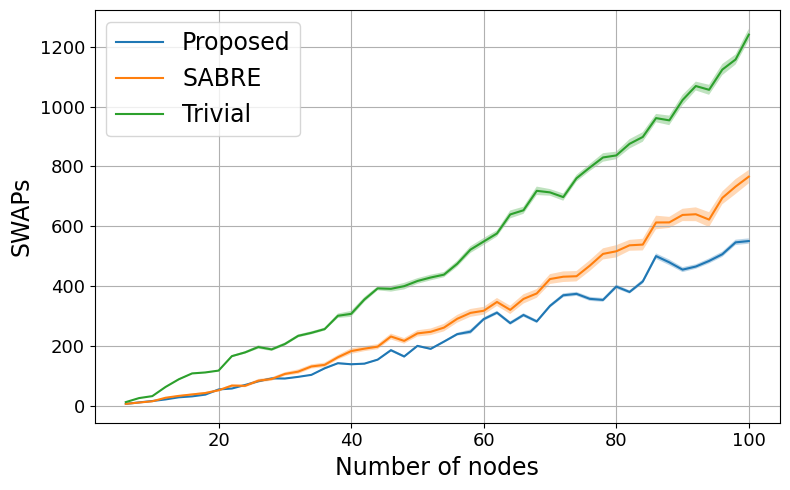

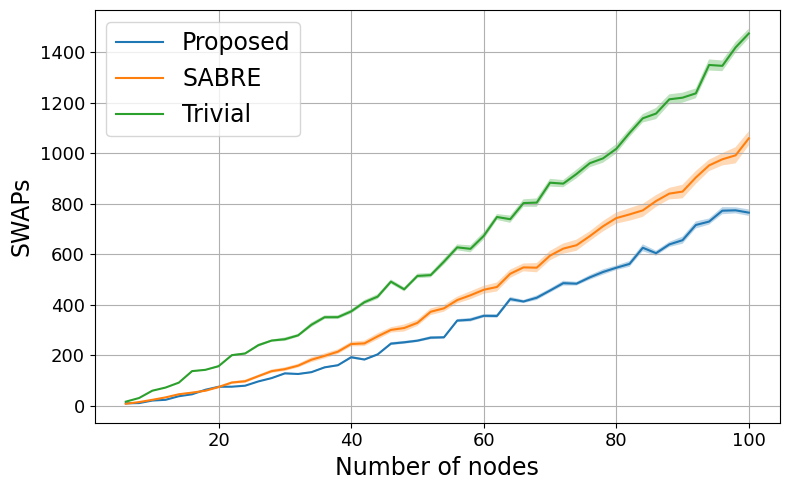

In [86]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_reg:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_reg[param]['means'][method])
        std = np.array(swaps_reg[param]['stddevs'][method])
        plt.plot(nodes_reg, mean, label=method)  # line for mean
        plt.fill_between(nodes_reg, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.legend(fontsize=17)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


ba graphs

Fiedler Mapped

In [56]:
import matplotlib.pyplot as plt

nodes_ba = list(range(6, 101, 2))
params_ba = list(range(2,5,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_ba={}
for param in params_ba:
    swaps_ba[param] = return_ops(backend, graph_type='ba', param=param, tree_type='dfs',
                         average_over=100, node_list=nodes_ba,
                         topology='tree_dfs', op_name='swap', tech='1D', use_custom=True, opt_level=3, stop_after_routing=True, reps=1)

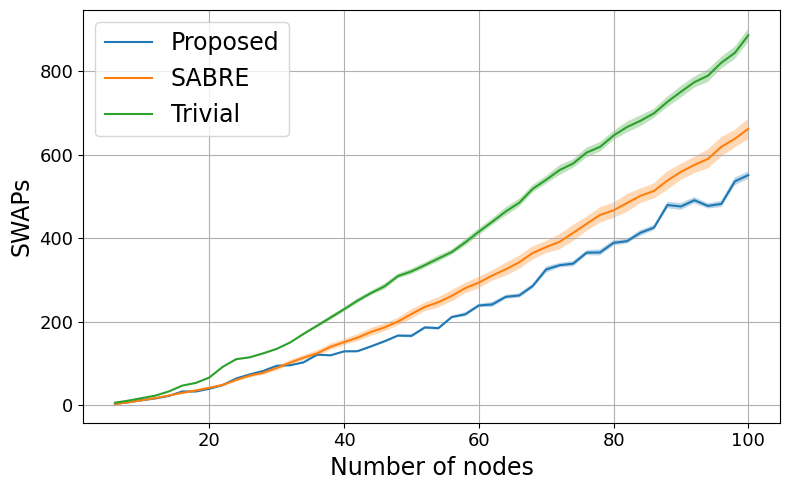

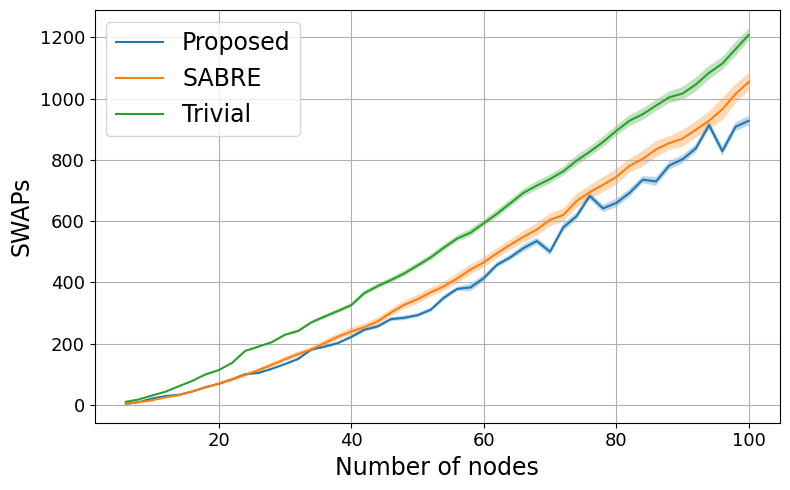

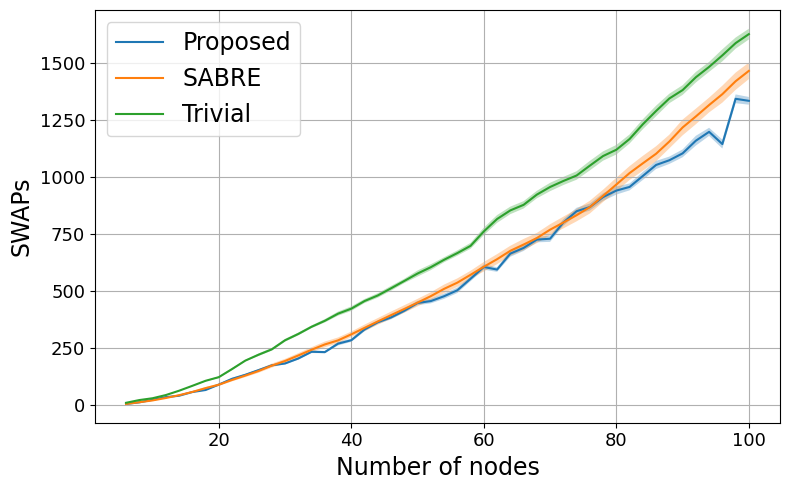

In [57]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_ba:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_ba[param]['means'][method])
        std = np.array(swaps_ba[param]['stddevs'][method])
        plt.plot(nodes_ba, mean, label=method)  # line for mean
        plt.fill_between(nodes_ba, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.legend(fontsize=17)
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


2D Mapped

In [87]:
import matplotlib.pyplot as plt

nodes_ba = list(range(6, 101, 2))
params_ba = list(range(2,5,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_ba={}
for param in params_ba:
    swaps_ba[param] = return_ops(backend, graph_type='ba', param=param,
                         average_over=100, node_list=nodes_ba,
                         topology='tree_dfs', op_name='swap', tech='2D', use_custom=True, opt_level=3, stop_after_routing=True, reps=1, k=2, normalize_graph=False)

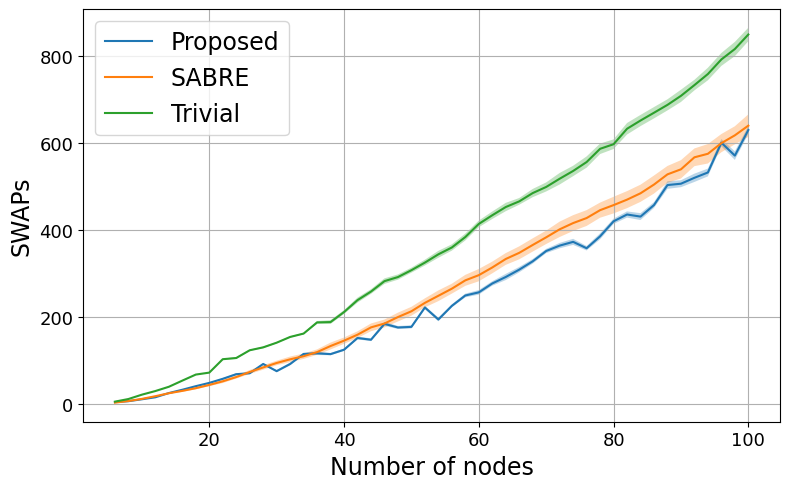

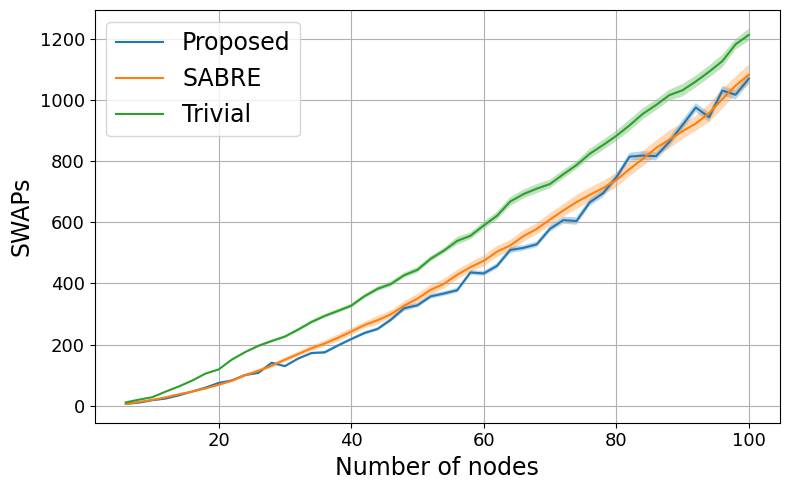

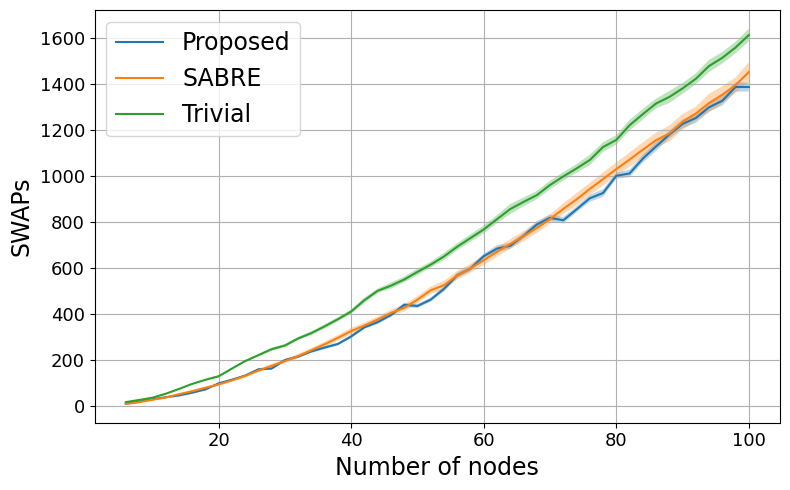

In [88]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_ba:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_ba[param]['means'][method])
        std = np.array(swaps_ba[param]['stddevs'][method])
        plt.plot(nodes_ba, mean, label=method)  # line for mean
        plt.fill_between(nodes_ba, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.legend(fontsize=17)
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


2D Mapped with normalized edges

In [89]:
import matplotlib.pyplot as plt

nodes_ba = list(range(6, 101, 2))
params_ba = list(range(2,5,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_ba={}
for param in params_ba:
    swaps_ba[param] = return_ops(backend, graph_type='ba', param=param,
                         average_over=100, node_list=nodes_ba,
                         topology='tree_dfs', op_name='swap', tech='2D', use_custom=True, opt_level=3, stop_after_routing=True, reps=1, k=2, normalize_graph=True)

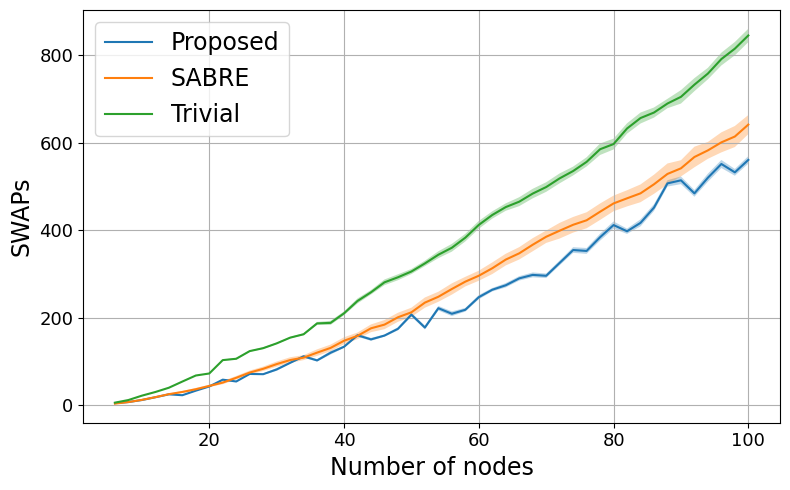

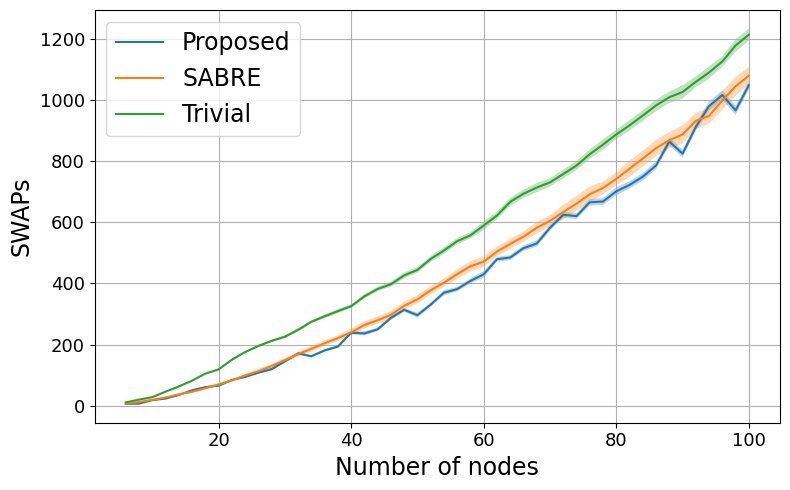

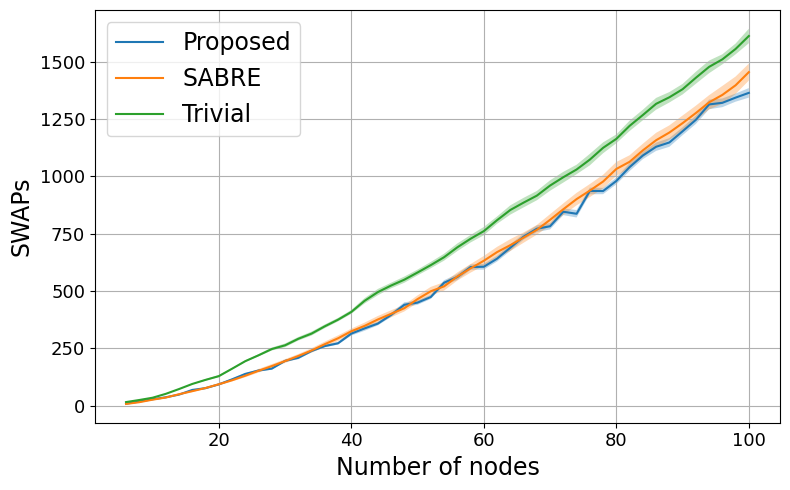

In [90]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_ba:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_ba[param]['means'][method])
        std = np.array(swaps_ba[param]['stddevs'][method])
        plt.plot(nodes_ba, mean, label=method)  # line for mean
        plt.fill_between(nodes_ba, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.legend(fontsize=17)
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


2D Mapped with normalized laplacian

In [91]:
import matplotlib.pyplot as plt

nodes_ba = list(range(6, 101, 2))
params_ba = list(range(2,5,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_ba={}
for param in params_ba:
    swaps_ba[param] = return_ops(backend, graph_type='ba', param=param,
                         average_over=100, node_list=nodes_ba,
                         topology='tree_dfs', op_name='swap', tech='2D', use_custom=True, opt_level=3, stop_after_routing=True, reps=1, k=2, normalize_laplacian=True)

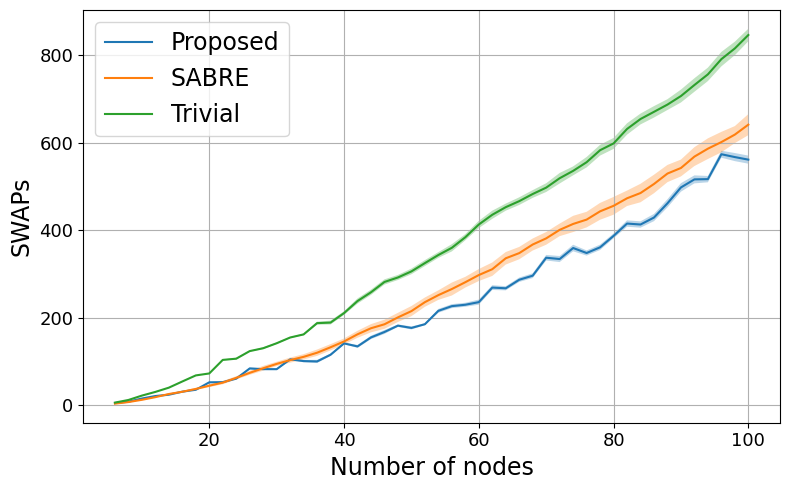

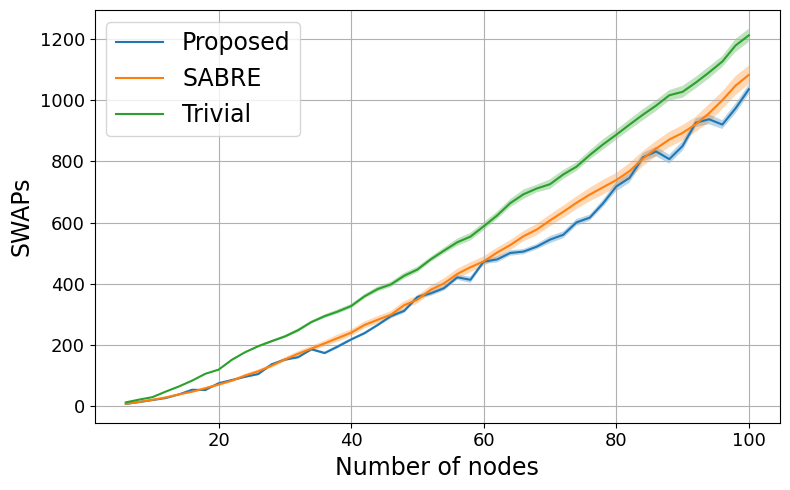

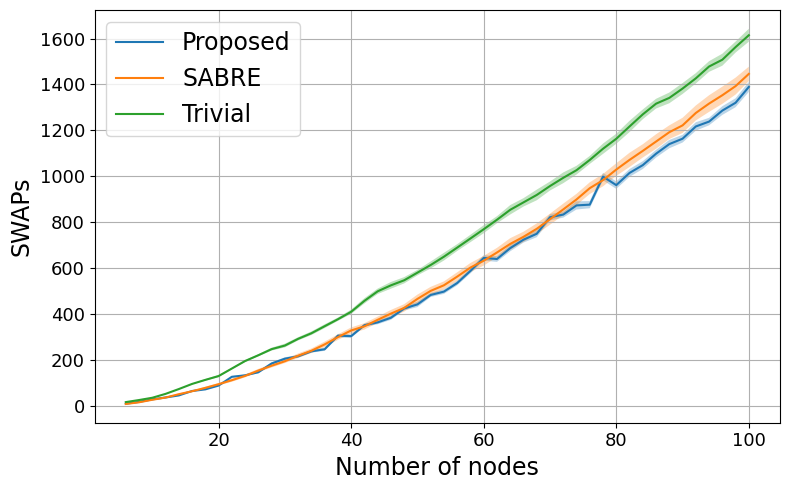

In [92]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_ba:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_ba[param]['means'][method])
        std = np.array(swaps_ba[param]['stddevs'][method])
        plt.plot(nodes_ba, mean, label=method)  # line for mean
        plt.fill_between(nodes_ba, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.legend(fontsize=17)
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


3D Mapped

In [107]:
import matplotlib.pyplot as plt

nodes_ba = list(range(6, 101, 2))
params_ba = list(range(2,5,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_ba={}
for param in params_ba:
    swaps_ba[param] = return_ops(backend, graph_type='ba', param=param,
                         average_over=100, node_list=nodes_ba,
                         topology='tree_dfs', op_name='swap', tech='2D', use_custom=True, opt_level=3, stop_after_routing=True, reps=1, k=3, normalize_graph=True)

Iterating for number of nodes:   0%|          | 0/48 [00:00<?, ?it/s]

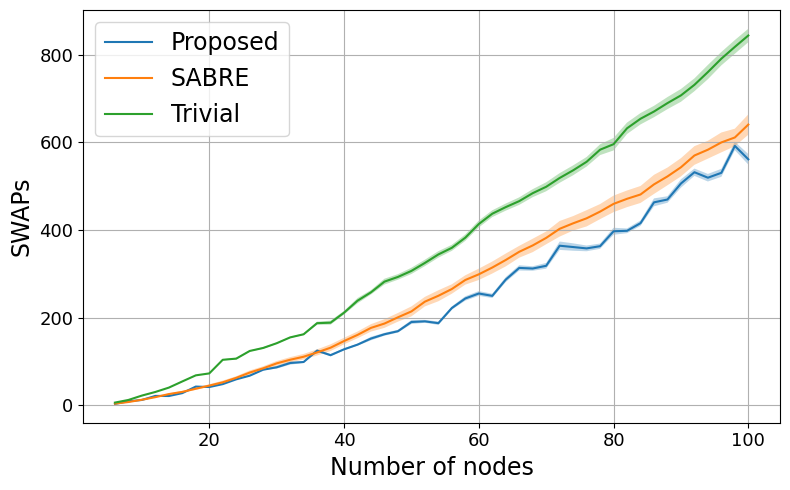

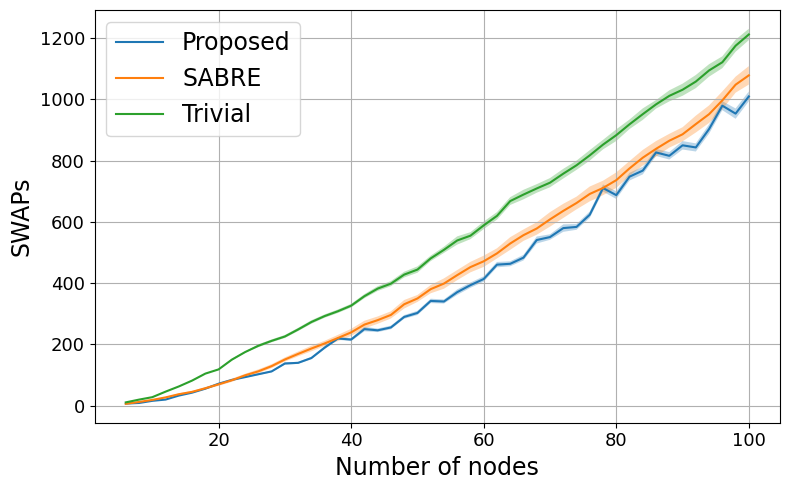

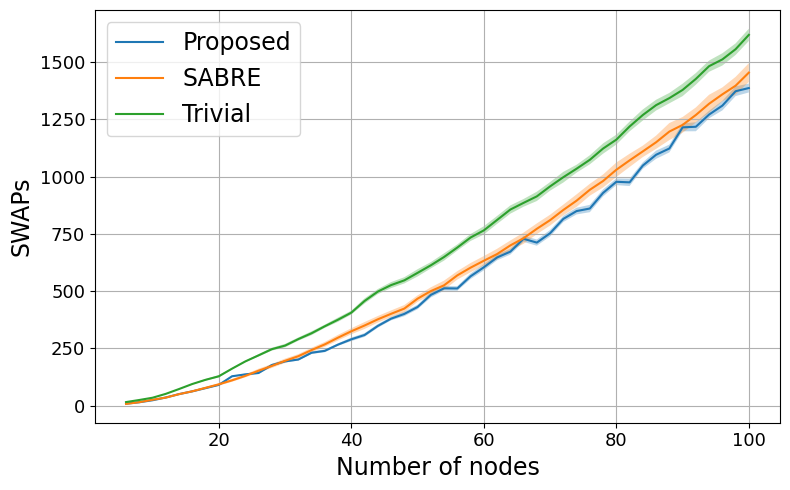

In [108]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_ba:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_ba[param]['means'][method])
        std = np.array(swaps_ba[param]['stddevs'][method])
        plt.plot(nodes_ba, mean, label=method)  # line for mean
        plt.fill_between(nodes_ba, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.legend(fontsize=17)
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


3D Mapped with normalized edges

In [109]:
import matplotlib.pyplot as plt

nodes_ba = list(range(6, 101, 2))
params_ba = list(range(2,5,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_ba={}
for param in params_ba:
    swaps_ba[param] = return_ops(backend, graph_type='ba', param=param,
                         average_over=100, node_list=nodes_ba,
                         topology='tree_dfs', op_name='swap', tech='2D', use_custom=True, opt_level=3, stop_after_routing=True, reps=1, k=3, normalize_graph=True)

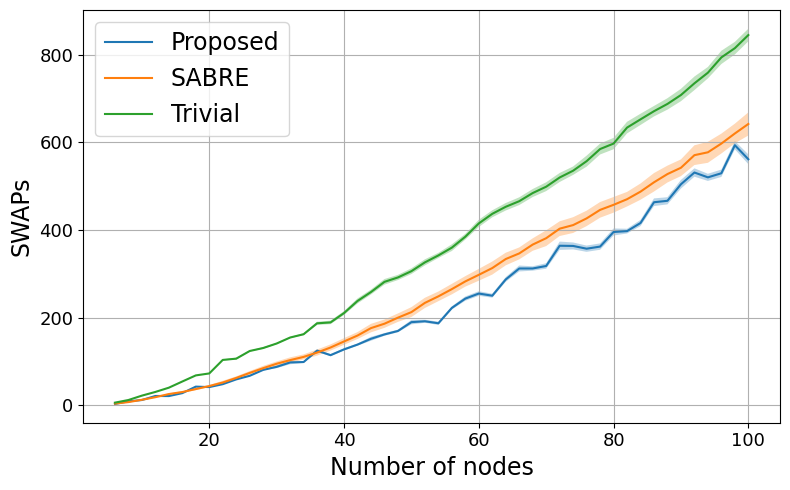

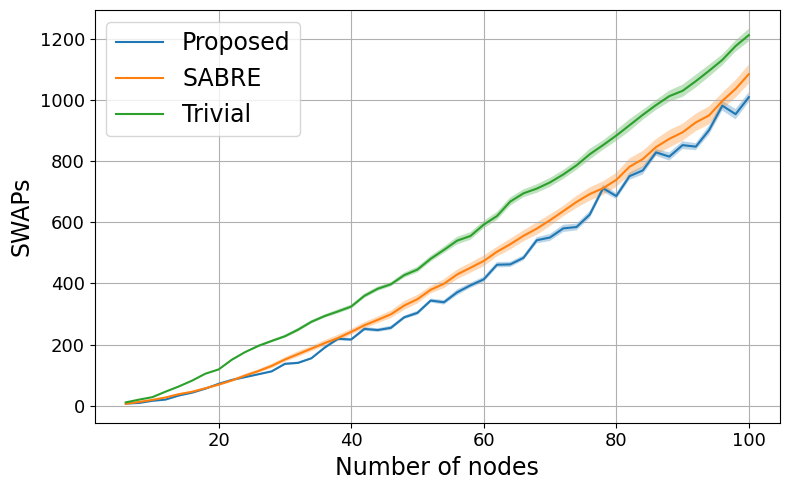

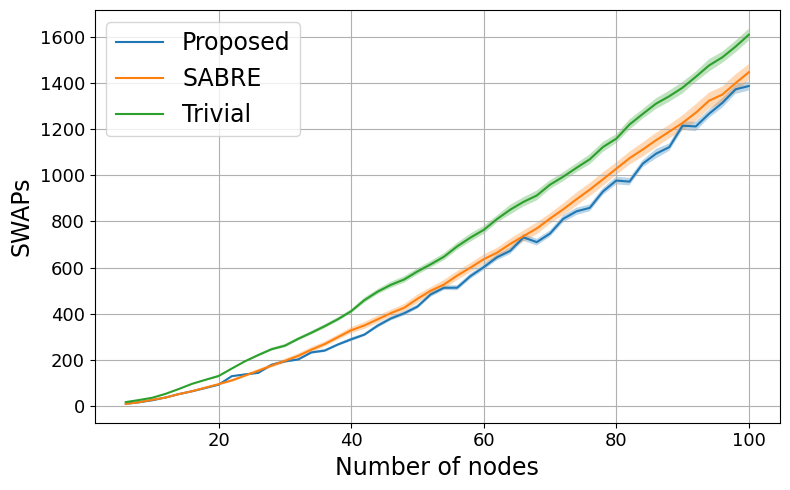

In [110]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_ba:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_ba[param]['means'][method])
        std = np.array(swaps_ba[param]['stddevs'][method])
        plt.plot(nodes_ba, mean, label=method)  # line for mean
        plt.fill_between(nodes_ba, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.legend(fontsize=17)
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


3D Mapped with normalized laplacian

In [ ]:
import matplotlib.pyplot as plt

nodes_ba = list(range(6, 101, 2))
params_ba = list(range(2,5,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_ba={}
for param in params_ba:
    swaps_ba[param] = return_ops(backend, graph_type='ba', param=param,
                         average_over=100, node_list=nodes_ba,
                         topology='tree_dfs', op_name='swap', tech='2D', use_custom=True, opt_level=3, stop_after_routing=True, reps=1, k=3, normalize_graph=False, normalize_laplacian=True)

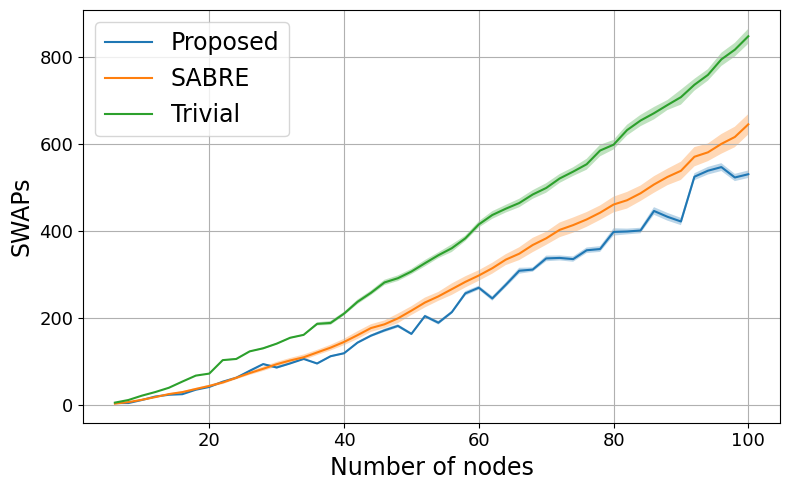

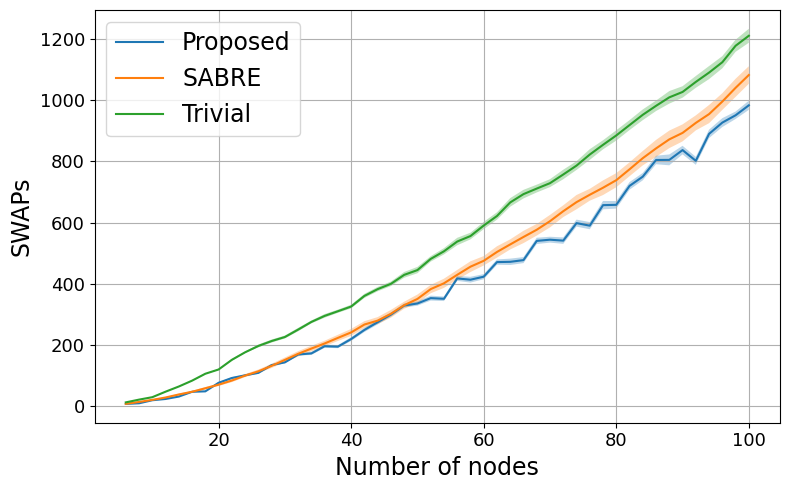

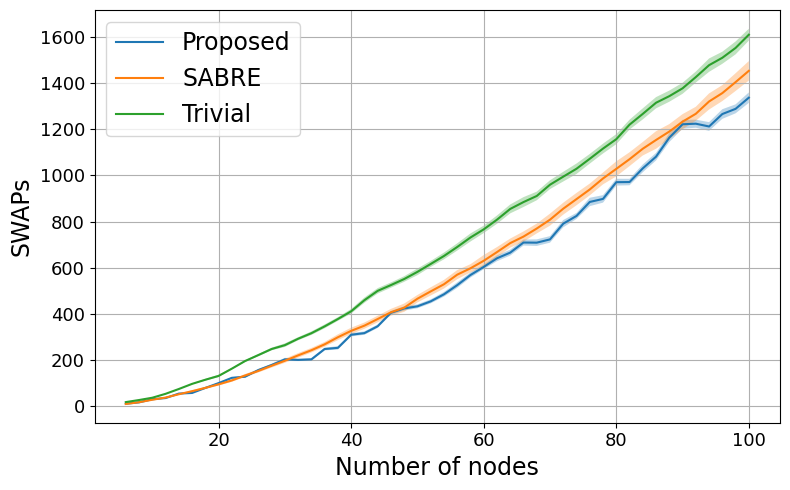

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_ba:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_ba[param]['means'][method])
        std = np.array(swaps_ba[param]['stddevs'][method])
        plt.plot(nodes_ba, mean, label=method)  # line for mean
        plt.fill_between(nodes_ba, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.legend(fontsize=17)
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


5D Mapped

In [93]:
import matplotlib.pyplot as plt

nodes_ba = list(range(6, 101, 2))
params_ba = list(range(2,5,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_ba={}
for param in params_ba:
    swaps_ba[param] = return_ops(backend, graph_type='ba', param=param,
                         average_over=100, node_list=nodes_ba,
                         topology='tree_dfs', op_name='swap', tech='2D', use_custom=True, opt_level=3, stop_after_routing=True, reps=1, k=5, normalize_graph=False)

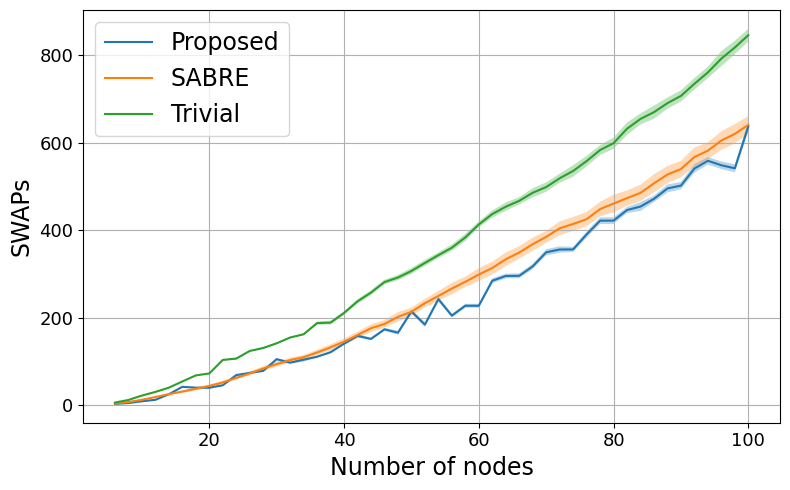

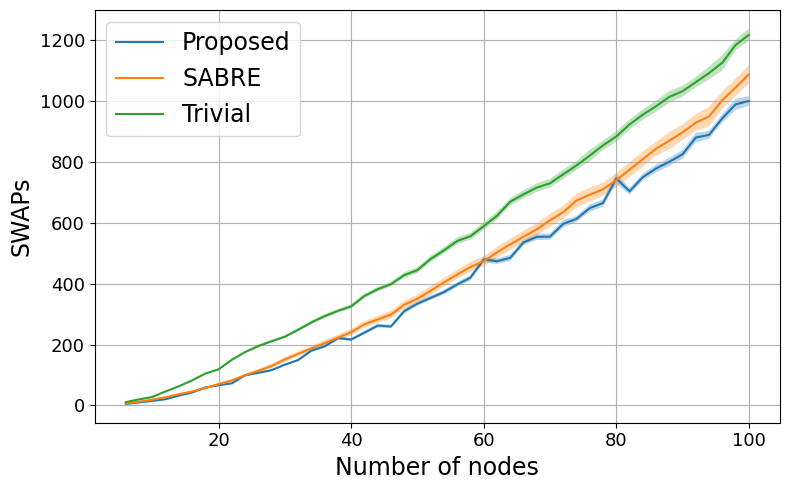

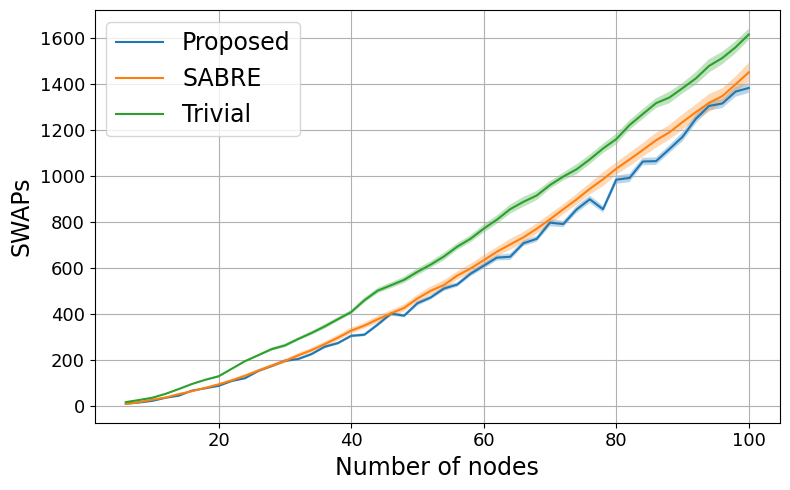

In [94]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_ba:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_ba[param]['means'][method])
        std = np.array(swaps_ba[param]['stddevs'][method])
        plt.plot(nodes_ba, mean, label=method)  # line for mean
        plt.fill_between(nodes_ba, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.legend(fontsize=17)
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


5D Mapped with normalized edges

In [95]:
import matplotlib.pyplot as plt

nodes_ba = list(range(6, 101, 2))
params_ba = list(range(2,5,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_ba={}
for param in params_ba:
    swaps_ba[param] = return_ops(backend, graph_type='ba', param=param,
                         average_over=100, node_list=nodes_ba,
                         topology='tree_dfs', op_name='swap', tech='2D', use_custom=True, opt_level=3, stop_after_routing=True, reps=1, k=5, normalize_graph=True)

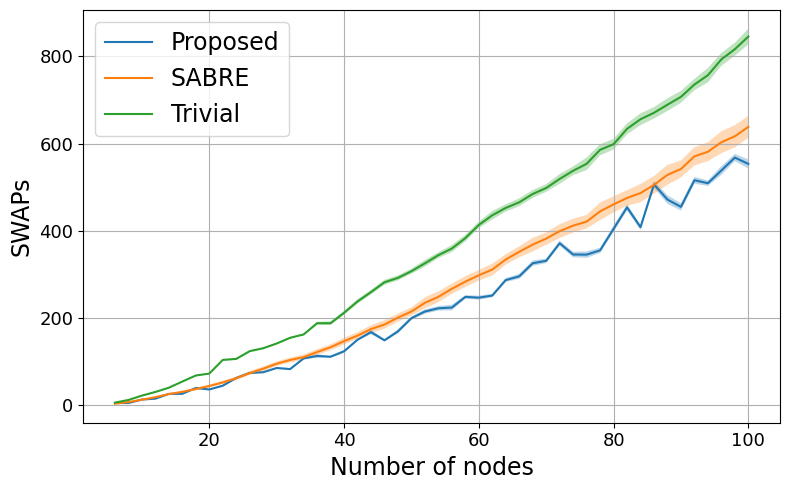

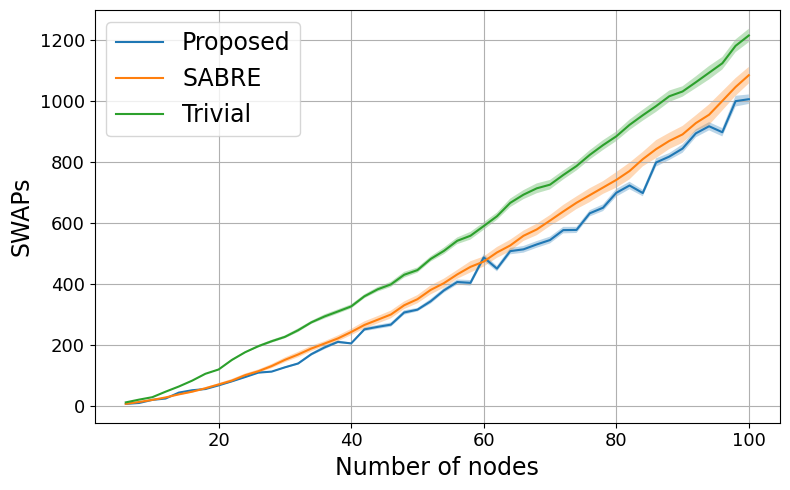

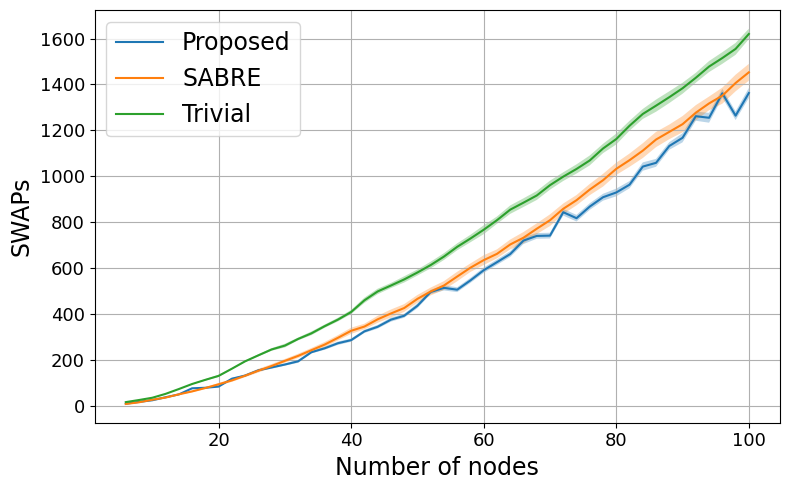

In [96]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_ba:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_ba[param]['means'][method])
        std = np.array(swaps_ba[param]['stddevs'][method])
        plt.plot(nodes_ba, mean, label=method)  # line for mean
        plt.fill_between(nodes_ba, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.legend(fontsize=17)
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


5D Mapped with normalized laplacian

In [97]:
import matplotlib.pyplot as plt

nodes_ba = list(range(6, 101, 2))
params_ba = list(range(2,5,1))
# params = [5]
strategies = ['Random', 'Proposed', 'SABRE', 'Trivial']  # Add 'cold' if needed
swaps_ba={}
for param in params_ba:
    swaps_ba[param] = return_ops(backend, graph_type='ba', param=param,
                         average_over=100, node_list=nodes_ba,
                         topology='tree_dfs', op_name='swap', tech='2D', use_custom=True, opt_level=3, stop_after_routing=True, reps=1, k=5, normalize_graph=False, normalize_laplacian=True)

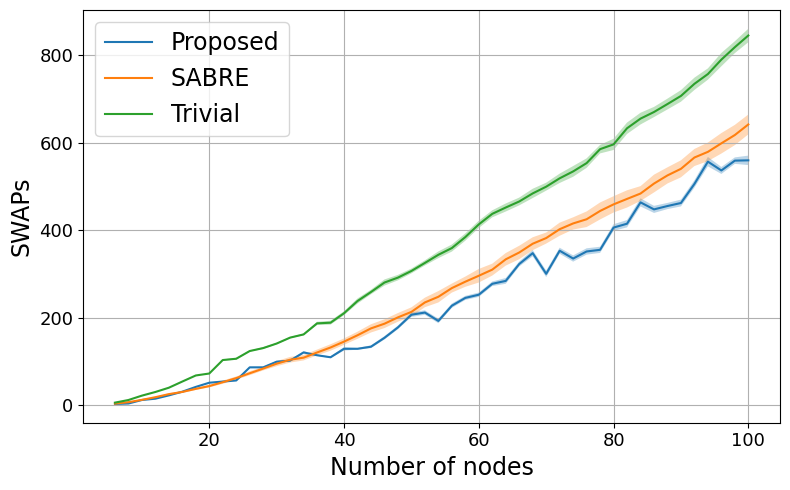

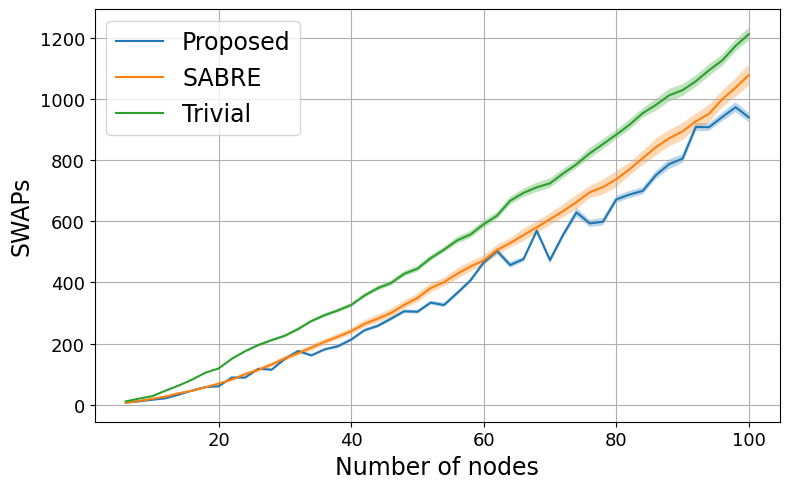

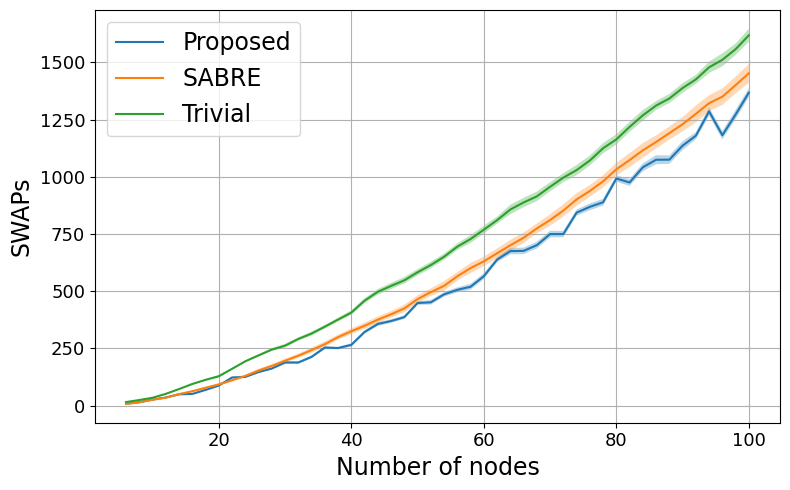

In [98]:
import matplotlib.pyplot as plt
import numpy as np

# Example data
methods = ["Proposed", "SABRE", "Trivial"]

# Plot
for param in params_ba:
    plt.figure(figsize=(8, 5))
    for method in methods:
        mean = np.array(swaps_ba[param]['means'][method])
        std = np.array(swaps_ba[param]['stddevs'][method])
        plt.plot(nodes_ba, mean, label=method)  # line for mean
        plt.fill_between(nodes_ba, mean - std, mean + std, alpha=0.3)  # shaded std band

    plt.xlabel("Number of nodes", fontsize=17)
    plt.ylabel("SWAPs", fontsize=17)
    # plt.title("Comparison of Initial Mappings with Error Bands")
    plt.legend(fontsize=17)
    plt.xticks(fontsize=13)                       # Increase x-tick label font size
    plt.yticks(fontsize=13)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


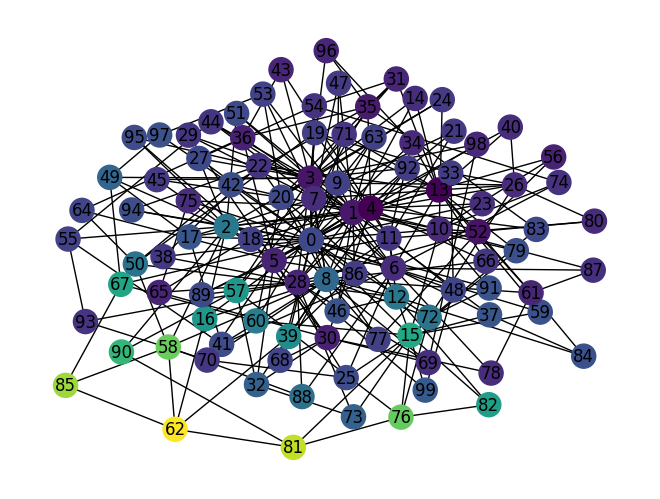

In [171]:
graph = barabasi_albert_graph(n=100, m=3, seed=0)
gradient_graph(graph, normalized=True, flip_sign=False)

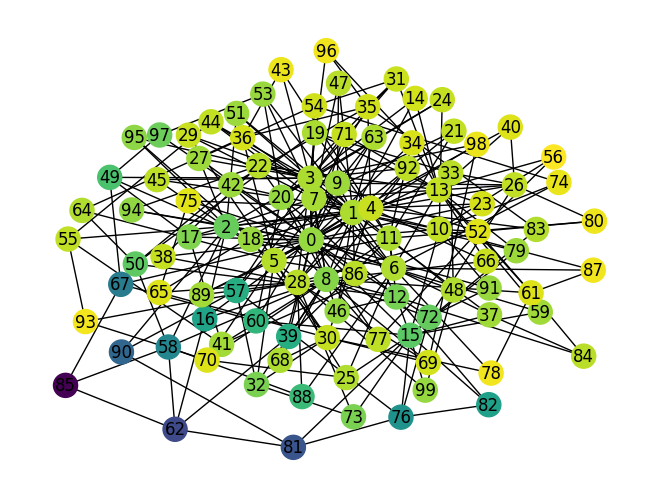

In [172]:
# graph = normalized_graph(graph)
graph = barabasi_albert_graph(n=100, m=3, seed=0)
gradient_graph(graph, normalized=False)

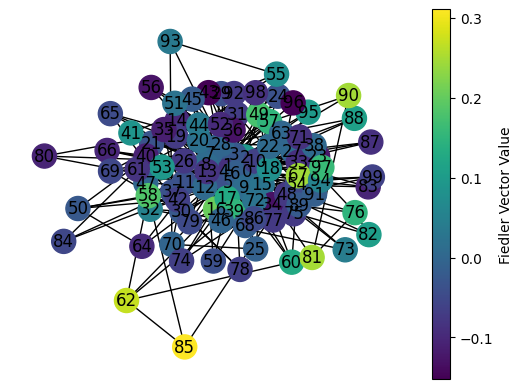

In [165]:
g = normalized_graph(graph)
gradient_graph(g)

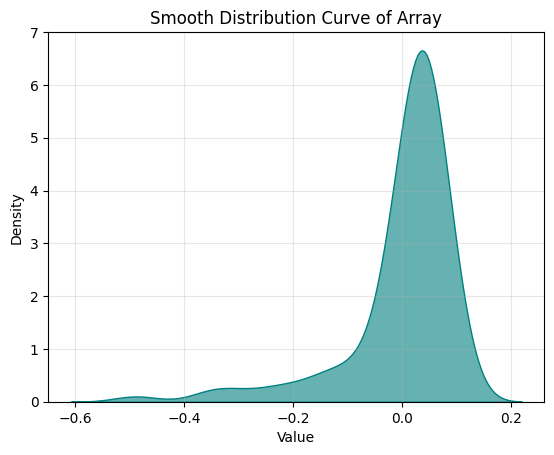

In [147]:
graph = barabasi_albert_graph(n=100, m=3, seed=0)
# graph = nx.random_regular_graph(n=100, d=3, seed=0)
logical_embedding = graph_laplacian_embedding(graph, normalized=False, k=1)
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

data = logical_embedding[:,0]

sns.kdeplot(data, fill=True, color='teal', alpha=0.6)
plt.xlabel("Value")
plt.ylabel("Density")
plt.title("Smooth Distribution Curve of Array")
plt.grid(alpha=0.3)
plt.ylim(top=7)
plt.show()


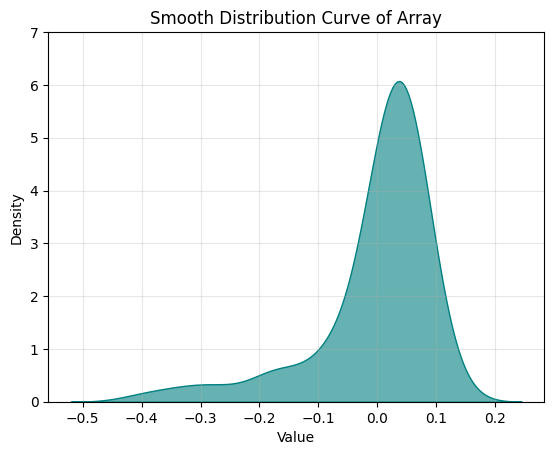

In [146]:
graph = barabasi_albert_graph(n=100, m=3, seed=0)
# graph = nx.random_regular_graph(n=100, d=3, seed=0)
logical_embedding = graph_laplacian_embedding(graph, normalized=True, k=1)
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

data = -logical_embedding[:,0]

sns.kdeplot(data, fill=True, color='teal', alpha=0.6)
plt.xlabel("Value")
plt.ylabel("Density")
plt.title("Smooth Distribution Curve of Array")
plt.grid(alpha=0.3)
plt.ylim(top=7)
plt.show()


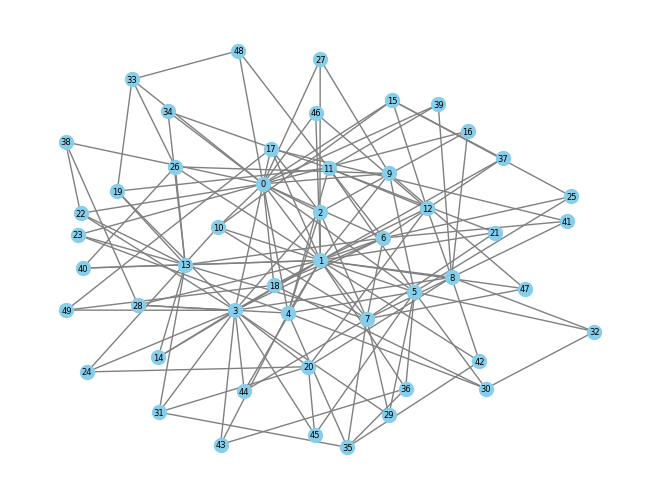

In [156]:
graph = barabasi_albert_graph(n=50, m=3, seed=0)
draw_graph_custom(graph)
# graph = nx.random_regular_graph(n=100, d=3, seed=0)
logical_embedding = graph_laplacian_embedding(graph, normalized=False, k=1)

In [158]:
list(graph.neighbors(0))

[1, 2, 3, 4, 5, 6, 9, 10, 15, 16, 17, 18, 22, 23, 27, 33, 34, 38, 39, 46, 48]